In [1]:
import sys
import numpy as np
import scipy
import gensim
import pandas as pd

print("Python:", sys.version)
print("Python executable:", sys.executable)
print("NumPy:", np.__version__)
print("SciPy:", scipy.__version__)
print("Gensim:", gensim.__version__)
print("Pandas:", pd.__version__)

Python: 3.11.0 (main, Oct 24 2022, 18:26:48) [MSC v.1933 64 bit (AMD64)]
Python executable: C:\Users\dell\NutriVision\.venv-word2vec\Scripts\python.exe
NumPy: 1.26.4
SciPy: 1.12.0
Gensim: 4.3.3
Pandas: 3.0.6


In [2]:
# --------------------------------------------------
# 2.2.10.1 Load the preprocessed Food.com corpus
# --------------------------------------------------

from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path(r"C:\Users\dell\NutriVision")

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "recipes"
    / "foodcom_nlp_preprocessed.csv.gz"
)

nlp_checkpoint = pd.read_csv(DATA_PATH)

print("Dataset shape:", nlp_checkpoint.shape)
print("\nColumns:", nlp_checkpoint.columns.tolist())
print("\nMissing processed texts:",
      nlp_checkpoint["processed_text"].isna().sum())

nlp_checkpoint.head()

Dataset shape: (231637, 5)

Columns: ['recipe_id', 'recipe_name', 'normalized_text', 'text_no_stopwords', 'processed_text']

Missing processed texts: 0


,recipe_id,recipe_name,normalized_text,text_no_stopwords,processed_text
0,137739,arriba baked winter squash mexican style,recipe arriba baked winter squash mexican styl...,arriba baked winter squash mexican style winte...,arriba bake winter squash mexican style winter...
1,31490,a bit different breakfast pizza,recipe a bit different breakfast pizza ingredi...,bit different breakfast pizza prepared pizza c...,bit different breakfast pizza prepare pizza cr...
2,112140,all in the kitchen chili,recipe all in the kitchen chili ingredients gr...,kitchen chili ground beef yellow onions diced ...,kitchen chili ground beef yellow onion dice to...
3,59389,alouette potatoes,recipe alouette potatoes ingredients spreadabl...,alouette potatoes spreadable cheese garlic her...,alouette potato spreadable cheese garlic herb ...
4,44061,amish tomato ketchup for canning,recipe amish tomato ketchup for canning ingred...,amish tomato ketchup canning tomato juice appl...,amish tomato ketchup can tomato juice apple ci...


In [3]:
# --------------------------------------------------
# 2.2.10.2 Prepare tokenized sentences
# --------------------------------------------------

class RecipeSentences:
    def __init__(self, texts):
        self.texts = texts

    def __iter__(self):
        for text in self.texts:
            yield text.split()


sentences = RecipeSentences(nlp_checkpoint["processed_text"])

# Inspect a few recipes
for i, tokens in enumerate(sentences):
    print(f"Recipe {i + 1}:")
    print(tokens[:20])
    print("Number of tokens:", len(tokens))
    print()

    if i == 2:
        break

Recipe 1:
['arriba', 'bake', 'winter', 'squash', 'mexican', 'style', 'winter', 'squash', 'mexican', 'seasoning', 'mixed', 'spice', 'honey', 'butter', 'olive', 'oil', 'salt', 'make', 'choice', 'proceed']
Number of tokens: 103

Recipe 2:
['bit', 'different', 'breakfast', 'pizza', 'prepare', 'pizza', 'crust', 'sausage', 'patty', 'egg', 'milk', 'salt', 'pepper', 'cheese', 'preheat', 'oven', '425', 'degree', 'f', 'press']
Number of tokens: 71

Recipe 3:
['kitchen', 'chili', 'ground', 'beef', 'yellow', 'onion', 'dice', 'tomato', 'tomato', 'paste', 'tomato', 'soup', 'rotel', 'tomato', 'kidney', 'bean', 'water', 'chili', 'powder', 'ground']
Number of tokens: 64



In [4]:
# --------------------------------------------------
# 2.2.10.3 Initialize Word2Vec and build vocabulary
# --------------------------------------------------

from gensim.models import Word2Vec

word2vec_model = Word2Vec(
    vector_size=100,
    window=5,
    min_count=2,
    workers=4,
    sg=1,
    seed=42
)

# Build vocabulary from the Food.com corpus
word2vec_model.build_vocab(sentences)

print("Vocabulary size:", len(word2vec_model.wv))
print("Total words:", word2vec_model.corpus_total_words)
print("Number of recipes:", word2vec_model.corpus_count)

Vocabulary size: 26869
Total words: 20103415
Number of recipes: 231637


In [5]:
# --------------------------------------------------
# 2.2.10.4 Train Word2Vec
# --------------------------------------------------

import time

start_time = time.time()

word2vec_model.train(
    sentences,
    total_examples=word2vec_model.corpus_count,
    epochs=10
)

training_time = time.time() - start_time

print(f"Training completed in {training_time / 60:.2f} minutes")
print("Vocabulary size:", len(word2vec_model.wv))
print("Vector dimensions:", word2vec_model.vector_size)

Training completed in 7.56 minutes
Vocabulary size: 26869
Vector dimensions: 100


In [6]:
# --------------------------------------------------
# 2.2.10.5 Inspect Word2Vec similarities
# --------------------------------------------------

test_words = ["chicken", "beef", "tomato", "cheese", "potato"]

for word in test_words:
    print(f"\nWords most similar to '{word}':")

    similar_words = word2vec_model.wv.most_similar(
        word,
        topn=10
    )

    for similar_word, similarity in similar_words:
        print(f"{similar_word:<20} {similarity:.4f}")


Words most similar to 'chicken':
breast               0.8096
thigh                0.7532
thighs               0.7497
oam                  0.6861
drumstick            0.6611
pheasant             0.6604
bulgoki              0.6593
skinless             0.6534
scala                0.6531
turkey               0.6515

Words most similar to 'beef':
chuck                0.8163
meat                 0.7687
sirloin              0.7558
venison              0.7129
hamburger            0.6948
bunkhouse            0.6664
pork                 0.6627
hamburg              0.6483
elk                  0.6439
mititei              0.6434

Words most similar to 'tomato':
tomatoes             0.8219
tomatoe              0.7981
oregano              0.6985
murciano             0.6851
contadina            0.6817
dice                 0.6759
basil                0.6675
rom                  0.6565
tomoatoes            0.6541
tomatilla            0.6520

Words most similar to 'cheese':
chesse               0.7729
m

In [7]:
# --------------------------------------------------
# 2.2.10.6 Create recipe-level embeddings
# --------------------------------------------------

import numpy as np

def get_recipe_vector(text, model):
    tokens = text.split()

    vectors = [
        model.wv[word]
        for word in tokens
        if word in model.wv
    ]

    if not vectors:
        return np.zeros(model.vector_size, dtype=np.float32)

    return np.mean(vectors, axis=0)


recipe_vectors = np.vstack([
    get_recipe_vector(text, word2vec_model)
    for text in nlp_checkpoint["processed_text"]
])

print("Recipe embeddings shape:", recipe_vectors.shape)
print("Data type:", recipe_vectors.dtype)
print("Total recipes:", len(recipe_vectors))
print("Vector dimensions:", recipe_vectors.shape[1])

Recipe embeddings shape: (231637, 100)
Data type: float32
Total recipes: 231637
Vector dimensions: 100


In [9]:
# --------------------------------------------------
# 2.2.10.7 Normalize recipe embeddings
# --------------------------------------------------

from sklearn.preprocessing import normalize

recipe_vectors_normalized = normalize(
    recipe_vectors,
    norm="l2",
    axis=1
)

print("Normalized embeddings shape:",
      recipe_vectors_normalized.shape)

print("First 5 vector norms:",
      np.linalg.norm(recipe_vectors_normalized[:5], axis=1))

print("Data type:", recipe_vectors_normalized.dtype)

Normalized embeddings shape: (231637, 100)
First 5 vector norms: [0.99999994 0.99999994 1.         1.         0.9999999 ]
Data type: float32


In [10]:
# --------------------------------------------------
# 2.2.10.8 Test recipe similarity
# --------------------------------------------------

from sklearn.metrics.pairwise import cosine_similarity

# Select the first recipe as an example
query_idx = 0

similarities = cosine_similarity(
    recipe_vectors_normalized[query_idx:query_idx + 1],
    recipe_vectors_normalized
)[0]

# Retrieve the 6 most similar recipes, excluding itself
top_indices = np.argsort(similarities)[::-1][1:7]

print("Query recipe:")
print(nlp_checkpoint.loc[query_idx, "recipe_name"])

print("\nMost similar recipes:\n")

for rank, idx in enumerate(top_indices, start=1):
    print(f"{rank}. {nlp_checkpoint.loc[idx, 'recipe_name']}")
    print(f"   Recipe ID: {nlp_checkpoint.loc[idx, 'recipe_id']}")
    print(f"   Similarity: {similarities[idx]:.4f}")

Query recipe:
arriba   baked winter squash mexican style

Most similar recipes:

1. healthy stuffed patty pan squash
   Recipe ID: 385381
   Similarity: 0.9615
2. properly prepared spaghetti squash
   Recipe ID: 162765
   Similarity: 0.9585
3. kittencal s simple spaghetti squash   vegetarian
   Recipe ID: 314706
   Similarity: 0.9580
4. potato and kielbasa sausage bake  one pot meal
   Recipe ID: 290976
   Similarity: 0.9579
5. roasted juicy acorn squash
   Recipe ID: 179443
   Similarity: 0.9576
6. squashed squash   hubbard or butternut
   Recipe ID: 35397
   Similarity: 0.9571


In [11]:
# --------------------------------------------------
# 2.2.10.9 Analyze random recipe similarities
# --------------------------------------------------

import random

random.seed(42)

# Select 100 random recipes
random_indices = random.sample(
    range(len(recipe_vectors_normalized)),
    100
)

random_vectors = recipe_vectors_normalized[random_indices]

# Calculate pairwise cosine similarities
similarity_matrix = cosine_similarity(random_vectors)

# Extract upper triangle, excluding diagonal
upper_triangle = similarity_matrix[
    np.triu_indices(100, k=1)
]

print("Random recipe pair similarity statistics:")
print(f"Mean:   {np.mean(upper_triangle):.4f}")
print(f"Median: {np.median(upper_triangle):.4f}")
print(f"Min:    {np.min(upper_triangle):.4f}")
print(f"Max:    {np.max(upper_triangle):.4f}")
print(f"Std:    {np.std(upper_triangle):.4f}")

Random recipe pair similarity statistics:
Mean:   0.8348
Median: 0.8507
Min:    0.4810
Max:    0.9814
Std:    0.0829


In [12]:
# --------------------------------------------------
# 2.2.10.10 Calculate IDF weights for recipe words
# --------------------------------------------------

from sklearn.feature_extraction.text import TfidfVectorizer

tfidf_vectorizer = TfidfVectorizer(
    use_idf=True,
    norm=None,
    min_df=1
)

tfidf_vectorizer.fit(nlp_checkpoint["processed_text"])

idf_weights = dict(
    zip(
        tfidf_vectorizer.get_feature_names_out(),
        tfidf_vectorizer.idf_
    )
)

print("Number of words with IDF weights:", len(idf_weights))

for word in ["chicken", "squash", "add", "mix", "serve"]:
    print(f"{word:<15} IDF: {idf_weights.get(word, 'Not found')}")

Number of words with IDF weights: 54934
chicken         IDF: 2.794439647897045
squash          IDF: 5.446752246820261
add             IDF: 1.4644912598447
mix             IDF: 1.8652926614717305
serve           IDF: 1.8177647933089514


In [13]:
# --------------------------------------------------
# 2.2.10.11 Create TF-IDF-weighted Word2Vec embeddings
# --------------------------------------------------

def get_weighted_recipe_vector(text, model, idf_weights):
    tokens = text.split()

    weighted_vectors = []
    weights = []

    for word in tokens:
        if word in model.wv and word in idf_weights:
            weight = idf_weights[word]

            weighted_vectors.append(model.wv[word] * weight)
            weights.append(weight)

    if not weighted_vectors:
        return np.zeros(model.vector_size, dtype=np.float32)

    return (
        np.sum(weighted_vectors, axis=0)
        / np.sum(weights)
    )


weighted_recipe_vectors = np.vstack([
    get_weighted_recipe_vector(text, word2vec_model, idf_weights)
    for text in nlp_checkpoint["processed_text"]
])

print("Weighted embeddings shape:", weighted_recipe_vectors.shape)
print("Data type:", weighted_recipe_vectors.dtype)

Weighted embeddings shape: (231637, 100)
Data type: float32


In [14]:
# --------------------------------------------------
# 2.2.10.12 Normalize TF-IDF-weighted Word2Vec embeddings
# --------------------------------------------------

weighted_recipe_vectors_normalized = normalize(
    weighted_recipe_vectors,
    norm="l2",
    axis=1
)

print("Shape:", weighted_recipe_vectors_normalized.shape)
print("Data type:", weighted_recipe_vectors_normalized.dtype)

print(
    "First 5 vector norms:",
    np.linalg.norm(weighted_recipe_vectors_normalized[:5], axis=1)
)

Shape: (231637, 100)
Data type: float32
First 5 vector norms: [1.         0.99999994 1.         0.99999994 1.        ]


In [15]:
# --------------------------------------------------
# 2.2.10.13 Compare Word2Vec similarity distributions
# --------------------------------------------------

from sklearn.metrics.pairwise import cosine_similarity

# Reuse exactly the same 100 recipe indices
random_indices = random.Random(42).sample(
    range(len(recipe_vectors_normalized)),
    100
)

# Unweighted Word2Vec
unweighted_sample = recipe_vectors_normalized[random_indices]
unweighted_similarities = cosine_similarity(unweighted_sample)

# TF-IDF-weighted Word2Vec
weighted_sample = weighted_recipe_vectors_normalized[random_indices]
weighted_similarities = cosine_similarity(weighted_sample)

# Extract unique pairs, excluding self-similarity
upper_indices = np.triu_indices(100, k=1)

unweighted_scores = unweighted_similarities[upper_indices]
weighted_scores = weighted_similarities[upper_indices]

print("UNWEIGHTED WORD2VEC")
print("-------------------")
print("Mean:", round(unweighted_scores.mean(), 4))
print("Median:", round(np.median(unweighted_scores), 4))
print("Minimum:", round(unweighted_scores.min(), 4))
print("Maximum:", round(unweighted_scores.max(), 4))
print("Std:", round(unweighted_scores.std(), 4))

print("\nTF-IDF-WEIGHTED WORD2VEC")
print("------------------------")
print("Mean:", round(weighted_scores.mean(), 4))
print("Median:", round(np.median(weighted_scores), 4))
print("Minimum:", round(weighted_scores.min(), 4))
print("Maximum:", round(weighted_scores.max(), 4))
print("Std:", round(weighted_scores.std(), 4))

UNWEIGHTED WORD2VEC
-------------------
Mean: 0.8348
Median: 0.8507
Minimum: 0.481
Maximum: 0.9814
Std: 0.0829

TF-IDF-WEIGHTED WORD2VEC
------------------------
Mean: 0.7705
Median: 0.7861
Minimum: 0.3654
Maximum: 0.9711
Std: 0.0988


In [16]:
# --------------------------------------------------
# 2.2.10.14 Compare unweighted and weighted retrieval
# --------------------------------------------------

query_idx = 0
top_k = 6

# Calculate similarities
unweighted_scores = cosine_similarity(
    recipe_vectors_normalized[query_idx:query_idx + 1],
    recipe_vectors_normalized
)[0]

weighted_scores = cosine_similarity(
    weighted_recipe_vectors_normalized[query_idx:query_idx + 1],
    weighted_recipe_vectors_normalized
)[0]


def display_top_recipes(scores, checkpoint, query_idx, top_k=6):
    scores = scores.copy()
    scores[query_idx] = -1

    top_indices = np.argsort(scores)[::-1][:top_k]

    results = checkpoint.iloc[top_indices][
        ["recipe_id", "recipe_name"]
    ].copy()

    results["similarity"] = scores[top_indices]

    return results.reset_index(drop=True)


print("QUERY RECIPE:")
print(nlp_checkpoint.loc[query_idx, "recipe_name"])

print("\nUNWEIGHTED WORD2VEC RESULTS")
display(display_top_recipes(
    unweighted_scores,
    nlp_checkpoint,
    query_idx,
    top_k
))

print("\nTF-IDF-WEIGHTED WORD2VEC RESULTS")
display(display_top_recipes(
    weighted_scores,
    nlp_checkpoint,
    query_idx,
    top_k
))

QUERY RECIPE:
arriba   baked winter squash mexican style

UNWEIGHTED WORD2VEC RESULTS


,recipe_id,recipe_name,similarity
0,385381,healthy stuffed patty pan squash,0.961475
1,162765,properly prepared spaghetti squash,0.958542
2,314706,kittencal s simple spaghetti squash vegetarian,0.957993
3,290976,potato and kielbasa sausage bake one pot meal,0.957934
4,179443,roasted juicy acorn squash,0.957630
5,35397,squashed squash hubbard or butternut,0.957065



TF-IDF-WEIGHTED WORD2VEC RESULTS


,recipe_id,recipe_name,similarity
0,467357,autumn squash soup,0.950978
1,261222,butternut squash with whole wheat wild rice a...,0.950882
2,265685,roasted squash and carrot puree fat free,0.949860
3,112443,tsr version of boston market butternut squash ...,0.948937
4,35397,squashed squash hubbard or butternut,0.947553
5,208263,easy roasted butternut squash,0.947236


In [17]:
# --------------------------------------------------
# 2.2.10.15 Compare retrieval on 10 random recipes
# --------------------------------------------------

evaluation_indices = random.Random(42).sample(
    range(len(nlp_checkpoint)),
    10
)

comparison_results = []

for query_idx in evaluation_indices:

    # Unweighted similarities
    unweighted_scores = cosine_similarity(
        recipe_vectors_normalized[query_idx:query_idx + 1],
        recipe_vectors_normalized
    )[0]

    # Weighted similarities
    weighted_scores = cosine_similarity(
        weighted_recipe_vectors_normalized[query_idx:query_idx + 1],
        weighted_recipe_vectors_normalized
    )[0]

    # Exclude the query recipe itself
    unweighted_scores[query_idx] = -1
    weighted_scores[query_idx] = -1

    unweighted_top5 = np.argsort(unweighted_scores)[::-1][:5]
    weighted_top5 = np.argsort(weighted_scores)[::-1][:5]

    comparison_results.append({
        "query_recipe": nlp_checkpoint.iloc[query_idx]["recipe_name"],
        "unweighted_top5": [
            nlp_checkpoint.iloc[i]["recipe_name"]
            for i in unweighted_top5
        ],
        "weighted_top5": [
            nlp_checkpoint.iloc[i]["recipe_name"]
            for i in weighted_top5
        ]
    })

for i, result in enumerate(comparison_results, 1):

    print(f"\n{'=' * 80}")
    print(f"QUERY {i}: {result['query_recipe']}")

    print("\nUNWEIGHTED TOP 5:")
    for recipe in result["unweighted_top5"]:
        print("-", recipe)

    print("\nWEIGHTED TOP 5:")
    for recipe in result["weighted_top5"]:
        print("-", recipe)


QUERY 1: pumpkin  walnut  and zucchini pasta

UNWEIGHTED TOP 5:
- fettuccini with zucchini cream sauce
- tortellini with  white wine primavera
- penne   sausage in creamy parmesan sauce
- tomato   white bean vegetable soup  vegetarian
- cheesy polenta with rich tomato sauce

WEIGHTED TOP 5:
- pumpkin and rosemary pasta
- super quick tomato basil cream pasta  vegan
- zucchini   pasta  with basil cream
- tomato   white bean vegetable soup  vegetarian
- creamy mushroom alfredo sauce

QUERY 2: broccoli and pasta soup

UNWEIGHTED TOP 5:
- not your ordinary minestrone soup
- roasted garlic and vegetable soup with pasta
- darcy s pasta e fagioli
- pasta e fagioli  pasta   bean soup
- lentil soup with ditalini  aka  new year s soup

WEIGHTED TOP 5:
- roasted garlic and vegetable soup with pasta
- not your ordinary minestrone soup
- pasta with tomato and hidden vegetable sauce
- spinach and tomato sauce
- seafairers spaghetti

QUERY 3: apple cinnamon pancakes

UNWEIGHTED TOP 5:
- good for you 

In [18]:
# --------------------------------------------------
# 2.2.10.16 Measure overlap between retrieval methods
# --------------------------------------------------

overlap_results = []

for result in comparison_results:

    unweighted_set = set(result["unweighted_top5"])
    weighted_set = set(result["weighted_top5"])

    common_recipes = unweighted_set.intersection(weighted_set)

    overlap_results.append({
        "query": result["query_recipe"],
        "common_results": len(common_recipes),
        "overlap_percentage": len(common_recipes) / 5 * 100
    })

overlap_df = pd.DataFrame(overlap_results)

display(overlap_df)

print("\nAverage top-5 overlap:",
      round(overlap_df["overlap_percentage"].mean(), 2), "%")

,query,common_results,overlap_percentage
0,pumpkin walnut and zucchini pasta,1,20.0
1,broccoli and pasta soup,2,40.0
2,apple cinnamon pancakes,3,60.0
3,speedy weeknight chicken casserole,3,60.0
4,dijon crusted pork chops oamc,4,80.0
5,creme caramel chai smoothie,1,20.0
6,corned beef and cabbage soup,3,60.0
7,carol s brownie drops chocolate cookies,2,40.0
8,southwestern pulled pork,3,60.0
9,bon apptit s low fat banana bread,1,20.0



Average top-5 overlap: 46.0 %



## 2.2.10 Word2Vec Recipe Representations

### Objective
Learn distributed word representations from the Food.com recipe corpus and use them to create numerical representations of recipes for similarity-based retrieval.

### Training configuration
Word2Vec was trained on 231,637 preprocessed recipes using:

- Architecture: Skip-gram (`sg=1`)
- Vector dimensions: 100
- Context window: 5
- Minimum word frequency: 2
- Training epochs: 10
- Random seed: 42
- Vocabulary size: 26,869

### Recipe representation

Two approaches were investigated:

**1. Mean-pooled Word2Vec**

Each recipe vector is calculated by averaging the Word2Vec vectors of its tokens.

**2. TF-IDF-weighted Word2Vec**

Each word vector is weighted by its inverse document frequency before averaging. This gives more importance to distinctive words and less importance to common recipe vocabulary.

Both representations produce 100-dimensional recipe vectors and are L2-normalized for cosine similarity retrieval.

### Preliminary observations

- Word2Vec captures semantic and culinary relationships between words.
- Mean pooling produces high similarity scores even between randomly sampled recipes, indicating limited discrimination.
- TF-IDF weighting reduces the average similarity between random recipe pairs from 0.8348 to 0.7705.
- The two approaches achieved an average top-5 overlap of 46% across 10 exploratory queries.
- TF-IDF weighting produced more focused results for some queries, while mean pooling performed better for others.

### Limitations

- Mean pooling loses word order and recipe structure.
- Word2Vec similarities are learned from word co-occurrence, not explicit culinary knowledge.
- Common ingredients and recipe instructions can influence the resulting embeddings.
- Preliminary qualitative comparisons do not establish retrieval accuracy.

### Conclusion

Both mean-pooled and TF-IDF-weighted Word2Vec representations will be retained as candidate retrieval methods. Their final performance will be evaluated using the same benchmark and metrics as the other classical NLP representations.


In [19]:
# --------------------------------------------------
# Inspect NutriVision project structure
# --------------------------------------------------

from pathlib import Path

PROJECT_ROOT = Path(r"C:\Users\dell\NutriVision")

for folder in [
    "data/raw",
    "data/processed/recipes",
    "notebooks",
    "reports"
]:
    path = PROJECT_ROOT / folder

    print(f"\n{folder}")

    if path.exists():
        for item in sorted(path.iterdir()):
            print(" -", item.name)
    else:
        print(" Folder does not exist")


data/raw
 - .gitkeep
 - food11
 - food_com
 - usda_foundation

data/processed/recipes
 - foodcom_nlp_preprocessed.csv.gz
 - foodcom_recipes_master.csv

notebooks
 - .ipynb_checkpoints
 - 01_initial_data_inspection.ipynb
 - 02_food11_data_cleaning.ipynb
 - 03_usda_data_preparation.ipynb
 - 04_curated_dataset_preparation.ipynb
 - 05_exploratory_data_analysis.ipynb
 - 06_classical_nlp.ipynb
 - 07_foodcom_dataset_inspection.ipynb
 - 08_foodcom_classical_retrieval.ipynb
 - 09_word2vec.ipynb

reports
 - Curated_Dataset_Preparation.md
 - Dataset_Description.md
 - figures


In [20]:
# --------------------------------------------------
# 2.3.1 Inspect structured recipe data
# --------------------------------------------------

MASTER_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "recipes"
    / "foodcom_recipes_master.csv"
)

master_sample = pd.read_csv(MASTER_PATH, nrows=5)

print("Available columns:")
print(master_sample.columns.tolist())

print("\nSample recipe information:")

for column in [
    "recipe_id",
    "recipe_name",
    "ingredients",
    "steps",
    "recipe_text_core"
]:
    if column in master_sample.columns:
        print(f"\n{column}:")
        print(master_sample[column].iloc[0])

Available columns:
['recipe_name', 'recipe_id', 'preparation_time_min', 'contributor_id', 'submitted', 'tags', 'nutrition', 'step_count', 'steps', 'description', 'ingredients', 'ingredient_count', 'calories_kcal', 'has_description', 'has_steps', 'has_ingredients', 'recipe_text', 'recipe_text_core', 'recipe_text_with_description', 'has_minimum_ingredients', 'has_preparation_steps', 'has_multiple_steps', 'has_valid_core_text']

Sample recipe information:

recipe_id:
137739

recipe_name:
arriba   baked winter squash mexican style

ingredients:
['winter squash', 'mexican seasoning', 'mixed spice', 'honey', 'butter', 'olive oil', 'salt']

steps:
['make a choice and proceed with recipe', 'depending on size of squash , cut into half or fourths', 'remove seeds', 'for spicy squash , drizzle olive oil or melted butter over each cut squash piece', 'season with mexican seasoning mix ii', 'for sweet squash , drizzle melted honey , butter , grated piloncillo over each cut squash piece', 'season with

In [21]:
# --------------------------------------------------
# 2.3.2 Verify structured ingredient parsing
# --------------------------------------------------

import ast

for idx, row in master_sample.iterrows():

    raw_ingredients = row["ingredients"]

    parsed_ingredients = ast.literal_eval(raw_ingredients)

    print(f"\nRecipe: {row['recipe_name']}")
    print("Parsed type:", type(parsed_ingredients))
    print("Ingredient count:", len(parsed_ingredients))
    print("Ingredients:", parsed_ingredients)


Recipe: arriba   baked winter squash mexican style
Parsed type: <class 'list'>
Ingredient count: 7
Ingredients: ['winter squash', 'mexican seasoning', 'mixed spice', 'honey', 'butter', 'olive oil', 'salt']

Recipe: a bit different  breakfast pizza
Parsed type: <class 'list'>
Ingredient count: 6
Ingredients: ['prepared pizza crust', 'sausage patty', 'eggs', 'milk', 'salt and pepper', 'cheese']

Recipe: all in the kitchen  chili
Parsed type: <class 'list'>
Ingredient count: 13
Ingredients: ['ground beef', 'yellow onions', 'diced tomatoes', 'tomato paste', 'tomato soup', 'rotel tomatoes', 'kidney beans', 'water', 'chili powder', 'ground cumin', 'salt', 'lettuce', 'cheddar cheese']

Recipe: alouette  potatoes
Parsed type: <class 'list'>
Ingredient count: 11
Ingredients: ['spreadable cheese with garlic and herbs', 'new potatoes', 'shallots', 'parsley', 'tarragon', 'olive oil', 'red wine vinegar', 'salt', 'pepper', 'red bell pepper', 'yellow bell pepper']

Recipe: amish  tomato ketchup  for

In [22]:
# --------------------------------------------------
# 2.3.3 Load and parse Food.com ingredients
# --------------------------------------------------

import ast
import pandas as pd

ingredient_df = pd.read_csv(
    MASTER_PATH,
    usecols=["recipe_id", "recipe_name", "ingredients"]
)

def parse_ingredients(value):
    try:
        parsed = ast.literal_eval(value)

        if isinstance(parsed, list):
            return [
                str(item).strip().lower()
                for item in parsed
                if isinstance(item, str) and item.strip()
            ]

        return []

    except (ValueError, SyntaxError, TypeError):
        return []


ingredient_df["parsed_ingredients"] = (
    ingredient_df["ingredients"].apply(parse_ingredients)
)

print("Dataset shape:", ingredient_df.shape)
print("Missing recipe IDs:", ingredient_df["recipe_id"].isna().sum())
print("Empty ingredient lists:",
      (ingredient_df["parsed_ingredients"].str.len() == 0).sum())

print("\nIngredient count distribution:")
print(ingredient_df["parsed_ingredients"].str.len().describe())

print("\nSample parsed recipes:")
display(
    ingredient_df[
        ["recipe_id", "recipe_name", "parsed_ingredients"]
    ].head(5)
)

Dataset shape: (231637, 4)
Missing recipe IDs: 0
Empty ingredient lists: 0

Ingredient count distribution:
count    231637.000000
mean          9.051153
std           3.734796
min           1.000000
25%           6.000000
50%           9.000000
75%          11.000000
max          43.000000
Name: parsed_ingredients, dtype: float64

Sample parsed recipes:


,recipe_id,recipe_name,parsed_ingredients
0,137739,arriba baked winter squash mexican style,"[winter squash, mexican seasoning, mixed spice..."
1,31490,a bit different breakfast pizza,"[prepared pizza crust, sausage patty, eggs, mi..."
2,112140,all in the kitchen chili,"[ground beef, yellow onions, diced tomatoes, t..."
3,59389,alouette potatoes,"[spreadable cheese with garlic and herbs, new ..."
4,44061,amish tomato ketchup for canning,"[tomato juice, apple cider vinegar, sugar, sal..."


In [23]:
# --------------------------------------------------
# 2.3.4 Identify eligible benchmark recipes
# --------------------------------------------------

ingredient_df["ingredient_count"] = (
    ingredient_df["parsed_ingredients"].str.len()
)

print("Total recipes:", len(ingredient_df))
print("Unique recipe IDs:", ingredient_df["recipe_id"].nunique())

for minimum in [3, 4, 5, 6, 7, 8]:
    eligible = (
        ingredient_df["ingredient_count"] >= minimum
    ).sum()

    percentage = eligible / len(ingredient_df) * 100

    print(
        f"At least {minimum} ingredients: "
        f"{eligible:,} recipes ({percentage:.2f}%)"
    )

Total recipes: 231637
Unique recipe IDs: 231637
At least 3 ingredients: 229,485 recipes (99.07%)
At least 4 ingredients: 222,685 recipes (96.14%)
At least 5 ingredients: 210,035 recipes (90.67%)
At least 6 ingredients: 191,818 recipes (82.81%)
At least 7 ingredients: 169,978 recipes (73.38%)
At least 8 ingredients: 145,379 recipes (62.76%)


In [24]:
# --------------------------------------------------
# 2.3.5 Select benchmark source recipes
# --------------------------------------------------

from sklearn.model_selection import train_test_split

# Keep recipes with at least 5 ingredients
eligible_recipes = ingredient_df[
    ingredient_df["ingredient_count"] >= 5
].copy()

# Select 1,000 unique source recipes
benchmark_sources = eligible_recipes.sample(
    n=1000,
    random_state=42
).reset_index(drop=True)

# Split into development and test sets
development_sources, test_sources = train_test_split(
    benchmark_sources,
    test_size=0.30,
    random_state=42
)

development_sources = development_sources.reset_index(drop=True)
test_sources = test_sources.reset_index(drop=True)

print("Selected benchmark sources:", len(benchmark_sources))
print("Development sources:", len(development_sources))
print("Test sources:", len(test_sources))

print(
    "\nShared recipe IDs:",
    len(
        set(development_sources["recipe_id"])
        & set(test_sources["recipe_id"])
    )
)

print("\nDevelopment sample:")
display(
    development_sources[
        ["recipe_id", "recipe_name", "ingredient_count"]
    ].head()
)

Selected benchmark sources: 1000
Development sources: 700
Test sources: 300

Shared recipe IDs: 0

Development sample:


,recipe_id,recipe_name,ingredient_count
0,300680,midori colada,5
1,103574,magi bread,14
2,104618,pork chops with star anise slow cooked,13
3,242753,how to prepare salt cod,8
4,210335,avocado mango bruschetta,8


In [25]:
# --------------------------------------------------
# 2.3.6 Generate synthetic ingredient queries
# --------------------------------------------------

import random
import math

def generate_queries(source_df, seed):
    rng = random.Random(seed)
    queries = []

    for _, row in source_df.iterrows():

        ingredients = row["parsed_ingredients"]
        n = len(ingredients)

        # Retain approximately half the ingredients
        query_count = min(
            n - 2,
            max(2, math.ceil(n * 0.5))
        )

        # Randomly select query ingredients
        selected_indices = sorted(
            rng.sample(range(n), query_count)
        )

        query_ingredients = [
            ingredients[i] for i in selected_indices
        ]

        hidden_ingredients = [
            ingredients[i]
            for i in range(n)
            if i not in selected_indices
        ]

        queries.append({
            "recipe_id": row["recipe_id"],
            "recipe_name": row["recipe_name"],
            "query_ingredients": query_ingredients,
            "hidden_ingredients": hidden_ingredients,
            "query_text": ", ".join(query_ingredients)
        })

    return pd.DataFrame(queries)


development_queries = generate_queries(
    development_sources, seed=42
)

test_queries = generate_queries(
    test_sources, seed=43
)

print("Development queries:", len(development_queries))
print("Test queries:", len(test_queries))

print("\nDevelopment query examples:")
display(development_queries.head(5))

Development queries: 700
Test queries: 300

Development query examples:


,recipe_id,recipe_name,query_ingredients,hidden_ingredients,query_text
0,300680,midori colada,"[coco lopez, rum, ice]","[midori melon liqueur, pineapple juice]","coco lopez, rum, ice"
1,103574,magi bread,"[sugar, eggs, vanilla, flaked coconut, marasch...","[butter, flour, semi-sweet chocolate chips, sl...","sugar, eggs, vanilla, flaked coconut, maraschi..."
2,104618,pork chops with star anise slow cooked,"[olive oil flavored cooking spray, pork chops,...","[chicken stock, soy sauce, palm sugar, five-sp...","olive oil flavored cooking spray, pork chops, ..."
3,242753,how to prepare salt cod,"[salt cod fish, white vinegar, onion, bay leaf]","[carrot, celery ribs, spices, dried parsley]","salt cod fish, white vinegar, onion, bay leaf"
4,210335,avocado mango bruschetta,"[extra virgin olive oil, fresh mango, red bell...","[ciabatta rolls, avocado, fresh basil, salt & ...","extra virgin olive oil, fresh mango, red bell ..."


In [28]:
# --------------------------------------------------
# 2.3.7 Inspect preprocessing code from notebook 08
# --------------------------------------------------

import json

PREPROCESSING_NOTEBOOK = (
    PROJECT_ROOT
    / "notebooks"
    / "08_foodcom_classical_retrieval.ipynb"
)

with open(PREPROCESSING_NOTEBOOK, "r", encoding="utf-8") as f:
    notebook_08 = json.load(f)

keywords = [
    "stopwords",
    "WordNetLemmatizer",
    "pos_tag",
    "spelling",
    "normalize_text",
    "processed_text"
]

for i, cell in enumerate(notebook_08["cells"]):
    if cell["cell_type"] != "code":
        continue

    source = "".join(cell["source"])

    if any(keyword in source for keyword in keywords):
        print(f"\n{'=' * 70}")
        print(f"CELL {i}")
        print(source[:6000])


CELL 12
# --------------------------------------------------
# 2.1.5 Basic Text Normalization
# --------------------------------------------------

import re
import string

def normalize_text(text):

    # Convert to lowercase
    text = text.lower()

    # Replace hyphens with spaces
    text = text.replace("-", " ")

    # Remove punctuation and special characters
    text = re.sub(r"[^a-z0-9\s]", " ", text)

    # Normalize repeated whitespace
    text = re.sub(r"\s+", " ", text).strip()

    return text


# Apply normalization
recipes_df["normalized_text"] = (
    recipes_df["recipe_text_core"].apply(normalize_text)
)


# Compare original and normalized examples
for idx in [0, 1, 2]:

    print("=" * 80)
    print("Recipe:", recipes_df.loc[idx, "recipe_name"])

    print("\nOriginal text:")
    print(recipes_df.loc[idx, "recipe_text_core"][:700])

    print("\nNormalized text:")
    print(recipes_df.loc[idx, "normalized_text"][:700])

CELL 18
import nltk

nltk.download("stopwords"

In [30]:
%pip install nltk

  Using cached nltk-3.10.4-py3-none-any.whl.metadata (5.0 kB)
  Using cached defusedxml-0.7.1-py2.py3-none-any.whl.metadata (32 kB)
  Using cached click-8.5.1-py3-none-any.whl.metadata (2.6 kB)
  Using cached tqdm-4.70.1-py3-none-any.whl.metadata (57 kB)
Using cached nltk-3.10.4-py3-none-any.whl (1.7 MB)
Using cached click-8.5.1-py3-none-any.whl (126 kB)
Using cached defusedxml-0.7.1-py2.py3-none-any.whl (25 kB)
Using cached tqdm-4.70.1-py3-none-any.whl (80 kB)

   -------- ------------------------------- 1/5 [regex]
   -------- ------------------------------- 1/5 [regex]
   ------------------------ --------------- 3/5 [click]
   -------------------------------- ------- 4/5 [nltk]
   -------------------------------- ------- 4/5 [nltk]
   -------------------------------- ------- 4/5 [nltk]
   -------------------------------- ------- 4/5 [nltk]
   -------------------------------- ------- 4/5 [nltk]
   -------------------------------- ------- 4/5 [nltk]
   --------------------------------

In [31]:
# --------------------------------------------------
# 2.3.8 Reproduce the Food.com Query Preprocessing
# --------------------------------------------------

import re
import nltk

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk import pos_tag

# Required NLTK resources for this environment
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("averaged_perceptron_tagger")
nltk.download("averaged_perceptron_tagger_eng")

# 1. Stopword configuration — copied from notebook 08

english_stopwords = set(stopwords.words("english"))

structural_stopwords = {
    "recipe",
    "ingredients",
    "preparation"
}

protected_words = {
    "not", "no", "nor", "never", "without",
    "until", "over", "into", "after", "before",
    "up", "down", "out", "off", "under",
    "each", "more", "less"
}

custom_stopwords = (
    english_stopwords
    .union(structural_stopwords)
    .difference(protected_words)
)

# 2. Lemmatizer

lemmatizer = WordNetLemmatizer()

def normalize_text(text):
    text = str(text).lower()
    text = text.replace("-", " ")
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

def lemmatize_tokens(tokens):
    tagged_tokens = pos_tag(tokens)

    lemmas = []

    for word, tag in tagged_tokens:
        if tag.startswith("V"):
            lemma = lemmatizer.lemmatize(word, pos="v")
        else:
            lemma = lemmatizer.lemmatize(word, pos="n")

        lemmas.append(lemma)

    return lemmas

# 3. Controlled spelling normalization

spelling_mapping = {
    "chilli": "chili",
    "yoghurt": "yogurt",
    "sautee": "saute",
    "barbeque": "barbecue",
    "catsup": "ketchup",
    "aubergine": "eggplant",
    "courgette": "zucchini"
}

# 4. Complete query preprocessing function

def preprocess_query(text):
    normalized = normalize_text(text)

    tokens = normalized.split()

    tokens_no_stopwords = [
        token for token in tokens
        if token not in custom_stopwords
    ]

    tokens_lemmatized = lemmatize_tokens(
        tokens_no_stopwords
    )

    tokens_normalized = [
        spelling_mapping.get(token, token)
        for token in tokens_lemmatized
    ]

    return " ".join(tokens_normalized)

print("Query preprocessing pipeline initialized.")
print("Number of stopwords:", len(custom_stopwords))
print("Protected words:", sorted(protected_words))

# Test on a sample query
sample_query = "Chicken breasts, chopped onions, and fresh tomatoes"

print("\nOriginal query:")
print(sample_query)

print("\nProcessed query:")
print(preprocess_query(sample_query))

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\dell\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\dell\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     C:\Users\dell\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping taggers\averaged_perceptron_tagger.zip.
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     C:\Users\dell\AppData\Roaming\nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     C:\Users\dell\AppData\Roaming\nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!


Query preprocessing pipeline initialized.
Number of stopwords: 186
Protected words: ['after', 'before', 'down', 'each', 'into', 'less', 'more', 'never', 'no', 'nor', 'not', 'off', 'out', 'over', 'under', 'until', 'up', 'without']

Original query:
Chicken breasts, chopped onions, and fresh tomatoes

Processed query:
chicken breast chop onion fresh tomato


In [32]:
# --------------------------------------------------
# 2.3.9 Preprocess Benchmark Queries
# --------------------------------------------------

development_queries["processed_query"] = (
    development_queries["query_text"].apply(preprocess_query)
)

test_queries["processed_query"] = (
    test_queries["query_text"].apply(preprocess_query)
)

print("Development queries:", len(development_queries))
print("Test queries:", len(test_queries))

print(
    "\nEmpty development queries:",
    (development_queries["processed_query"].str.strip() == "").sum()
)

print(
    "Empty test queries:",
    (test_queries["processed_query"].str.strip() == "").sum()
)

print("\nDevelopment examples:")

for _, row in development_queries.head(5).iterrows():
    print("\nRecipe:", row["recipe_name"])
    print("Original:", row["query_text"])
    print("Processed:", row["processed_query"])

print("\nTest examples:")

for _, row in test_queries.head(3).iterrows():
    print("\nRecipe:", row["recipe_name"])
    print("Original:", row["query_text"])
    print("Processed:", row["processed_query"])

Development queries: 700
Test queries: 300

Empty development queries: 0
Empty test queries: 0

Development examples:

Recipe: midori colada
Original: coco lopez, rum, ice
Processed: coco lopez rum ice

Recipe: magi bread
Original: sugar, eggs, vanilla, flaked coconut, maraschino cherry, fig, baking soda
Processed: sugar egg vanilla flake coconut maraschino cherry fig bake soda

Recipe: pork chops with star anise  slow cooked
Original: olive oil flavored cooking spray, pork chops, chinese wine, star anise, sambal oelek, honey, garlic cloves
Processed: olive oil flavor cooking spray pork chop chinese wine star anise sambal oelek honey garlic clove

Recipe: how to prepare salt cod
Original: salt cod fish, white vinegar, onion, bay leaf
Processed: salt cod fish white vinegar onion bay leaf

Recipe: avocado mango bruschetta
Original: extra virgin olive oil, fresh mango, red bell pepper, lime juice
Processed: extra virgin olive oil fresh mango red bell pepper lime juice

Test examples:

Rec

In [33]:
# --------------------------------------------------
# 2.3.10 Word2Vec Query Vocabulary Coverage
# --------------------------------------------------

def calculate_vocabulary_coverage(query_df, model):
    total_tokens = 0
    covered_tokens = 0
    unique_tokens = set()
    covered_unique_tokens = set()

    for query in query_df["processed_query"]:
        tokens = query.split()

        total_tokens += len(tokens)
        unique_tokens.update(tokens)

        known_tokens = [
            token for token in tokens
            if token in model.wv
        ]

        covered_tokens += len(known_tokens)
        covered_unique_tokens.update(known_tokens)

    return {
        "total_tokens": total_tokens,
        "covered_tokens": covered_tokens,
        "token_coverage": covered_tokens / total_tokens,
        "unique_tokens": len(unique_tokens),
        "covered_unique_tokens": len(covered_unique_tokens),
        "unique_coverage": (
            len(covered_unique_tokens) / len(unique_tokens)
        )
    }


dev_coverage = calculate_vocabulary_coverage(
    development_queries, word2vec_model
)

test_coverage = calculate_vocabulary_coverage(
    test_queries, word2vec_model
)

print("DEVELOPMENT VOCABULARY COVERAGE")
for key, value in dev_coverage.items():
    print(f"{key}: {value:.4f}" if isinstance(value, float) else f"{key}: {value}")

print("\nTEST VOCABULARY COVERAGE")
for key, value in test_coverage.items():
    print(f"{key}: {value:.4f}" if isinstance(value, float) else f"{key}: {value}")

DEVELOPMENT VOCABULARY COVERAGE
total_tokens: 6539
covered_tokens: 6539
token_coverage: 1.0000
unique_tokens: 731
covered_unique_tokens: 731
unique_coverage: 1.0000

TEST VOCABULARY COVERAGE
total_tokens: 2637
covered_tokens: 2637
token_coverage: 1.0000
unique_tokens: 503
covered_unique_tokens: 503
unique_coverage: 1.0000


In [34]:
# --------------------------------------------------
# 2.3.11 Build Word2Vec Query Vectors
# --------------------------------------------------

def get_query_vector(text, model, idf_weights=None):
    tokens = text.split()

    if idf_weights is None:
        vectors = [
            model.wv[word]
            for word in tokens
            if word in model.wv
        ]

        if not vectors:
            return np.zeros(model.vector_size, dtype=np.float32)

        return np.mean(vectors, axis=0)

    weighted_vectors = []
    weights = []

    for word in tokens:
        if word in model.wv and word in idf_weights:
            weight = idf_weights[word]

            weighted_vectors.append(
                model.wv[word] * weight
            )
            weights.append(weight)

    if not weighted_vectors:
        return np.zeros(model.vector_size, dtype=np.float32)

    return (
        np.sum(weighted_vectors, axis=0)
        / np.sum(weights)
    )


# Development query vectors
dev_query_vectors = np.vstack([
    get_query_vector(query, word2vec_model)
    for query in development_queries["processed_query"]
])

dev_query_vectors_weighted = np.vstack([
    get_query_vector(query, word2vec_model, idf_weights)
    for query in development_queries["processed_query"]
])


# Test query vectors
test_query_vectors = np.vstack([
    get_query_vector(query, word2vec_model)
    for query in test_queries["processed_query"]
])

test_query_vectors_weighted = np.vstack([
    get_query_vector(query, word2vec_model, idf_weights)
    for query in test_queries["processed_query"]
])


# L2 normalization
dev_query_vectors_normalized = normalize(
    dev_query_vectors, norm="l2", axis=1
)

dev_query_vectors_weighted_normalized = normalize(
    dev_query_vectors_weighted, norm="l2", axis=1
)

test_query_vectors_normalized = normalize(
    test_query_vectors, norm="l2", axis=1
)

test_query_vectors_weighted_normalized = normalize(
    test_query_vectors_weighted, norm="l2", axis=1
)


print("Development unweighted:", dev_query_vectors_normalized.shape)
print("Development weighted:", dev_query_vectors_weighted_normalized.shape)

print("Test unweighted:", test_query_vectors_normalized.shape)
print("Test weighted:", test_query_vectors_weighted_normalized.shape)

print("\nFirst development query vector norm:")
print(np.linalg.norm(dev_query_vectors_normalized[0]))

print("\nFirst weighted development query vector norm:")
print(np.linalg.norm(dev_query_vectors_weighted_normalized[0]))

Development unweighted: (700, 100)
Development weighted: (700, 100)
Test unweighted: (300, 100)
Test weighted: (300, 100)

First development query vector norm:
0.99999994

First weighted development query vector norm:
1.0


In [35]:
# --------------------------------------------------
# 2.3.12 Verify Recipe Vector Alignment
# --------------------------------------------------

print("Recipe checkpoint shape:", nlp_checkpoint.shape)
print("Recipe vector shape:", recipe_vectors_normalized.shape)
print("Weighted recipe vector shape:", weighted_recipe_vectors_normalized.shape)

print("\nFirst 5 recipe IDs:")
print(nlp_checkpoint["recipe_id"].head().tolist())

print("\nFirst 5 recipe names:")
print(nlp_checkpoint["recipe_name"].head().tolist())

print("\nNumber of unique recipe IDs:")
print(nlp_checkpoint["recipe_id"].nunique())

print("\nMissing recipe IDs:")
print(nlp_checkpoint["recipe_id"].isna().sum())

# Verify alignment
assert len(nlp_checkpoint) == len(recipe_vectors_normalized)
assert len(nlp_checkpoint) == len(weighted_recipe_vectors_normalized)
assert nlp_checkpoint["recipe_id"].is_unique

print("\nRecipe-vector alignment checks passed.")

Recipe checkpoint shape: (231637, 5)
Recipe vector shape: (231637, 100)
Weighted recipe vector shape: (231637, 100)

First 5 recipe IDs:
[137739, 31490, 112140, 59389, 44061]

First 5 recipe names:
['arriba   baked winter squash mexican style', 'a bit different  breakfast pizza', 'all in the kitchen  chili', 'alouette  potatoes', 'amish  tomato ketchup  for canning']

Number of unique recipe IDs:
231637

Missing recipe IDs:
0

Recipe-vector alignment checks passed.


In [36]:
# --------------------------------------------------
# 2.3.13 Word2Vec Retrieval Sanity Check
# --------------------------------------------------

def retrieve_word2vec(query_vector, recipe_matrix, top_k=5):
    scores = np.dot(recipe_matrix, query_vector)

    top_indices = np.argsort(scores)[-top_k:][::-1]

    results = nlp_checkpoint.iloc[top_indices][
        ["recipe_id", "recipe_name"]
    ].copy()

    results["similarity"] = scores[top_indices]

    return results, scores


# Test the first 5 development queries
for i in range(5):

    query = development_queries.iloc[i]
    source_id = query["recipe_id"]

    source_index = nlp_checkpoint.index[
        nlp_checkpoint["recipe_id"] == source_id
    ][0]

    print("\n" + "=" * 75)
    print(f"QUERY {i + 1}: {query['recipe_name']}")
    print("Ingredients:", query["query_text"])

    # Unweighted retrieval
    unweighted_results, unweighted_scores = retrieve_word2vec(
        dev_query_vectors_normalized[i],
        recipe_vectors_normalized
    )

    unweighted_rank = (
        np.sum(unweighted_scores > unweighted_scores[source_index]) + 1
    )

    print("\nUNWEIGHTED TOP 5")
    print(unweighted_results.to_string(index=False))
    print("Source recipe rank:", unweighted_rank)

    # Weighted retrieval
    weighted_results, weighted_scores = retrieve_word2vec(
        dev_query_vectors_weighted_normalized[i],
        weighted_recipe_vectors_normalized
    )

    weighted_rank = (
        np.sum(weighted_scores > weighted_scores[source_index]) + 1
    )

    print("\nTF-IDF-WEIGHTED TOP 5")
    print(weighted_results.to_string(index=False))
    print("Source recipe rank:", weighted_rank)


QUERY 1: midori colada
Ingredients: coco lopez, rum, ice

UNWEIGHTED TOP 5
 recipe_id                                                     recipe_name  similarity
    300680                                                   midori colada    0.890331
    222589                                        get your groove on punch    0.890097
    298166 bbc cocktail  baileys  banana  coco lopez  frozen dessert drink    0.871563
    249188                                             coco amaretto juice    0.871264
    219375                                                malibu parilyzer    0.867739
Source recipe rank: 1

TF-IDF-WEIGHTED TOP 5
 recipe_id                                                     recipe_name  similarity
    222589                                        get your groove on punch    0.932623
    149843                                                     painkillers    0.923396
    298166 bbc cocktail  baileys  banana  coco lopez  frozen dessert drink    0.906661
     7239

In [37]:
# --------------------------------------------------
# 2.3.14 Inspect Recipe Text Sources
# --------------------------------------------------

print("MASTER DATASET COLUMNS:")
print(ingredient_df.columns.tolist())

print("\nPREPROCESSED NLP CHECKPOINT:")
print(nlp_checkpoint.columns.tolist())

print("\nSAMPLE INGREDIENT LISTS:")

for _, row in ingredient_df.head(5).iterrows():
    print("\nRecipe ID:", row["recipe_id"])
    print("Recipe:", row["recipe_name"])
    print("Ingredients:", row["parsed_ingredients"])

print("\nCHECKPOINT SAMPLE:")

for _, row in nlp_checkpoint.head(5).iterrows():
    print("\nRecipe ID:", row["recipe_id"])
    print("Recipe:", row["recipe_name"])
    print("Processed text:", row["processed_text"][:250])

MASTER DATASET COLUMNS:
['recipe_name', 'recipe_id', 'ingredients', 'parsed_ingredients', 'ingredient_count']

PREPROCESSED NLP CHECKPOINT:
['recipe_id', 'recipe_name', 'normalized_text', 'text_no_stopwords', 'processed_text']

SAMPLE INGREDIENT LISTS:

Recipe ID: 137739
Recipe: arriba   baked winter squash mexican style
Ingredients: ['winter squash', 'mexican seasoning', 'mixed spice', 'honey', 'butter', 'olive oil', 'salt']

Recipe ID: 31490
Recipe: a bit different  breakfast pizza
Ingredients: ['prepared pizza crust', 'sausage patty', 'eggs', 'milk', 'salt and pepper', 'cheese']

Recipe ID: 112140
Recipe: all in the kitchen  chili
Ingredients: ['ground beef', 'yellow onions', 'diced tomatoes', 'tomato paste', 'tomato soup', 'rotel tomatoes', 'kidney beans', 'water', 'chili powder', 'ground cumin', 'salt', 'lettuce', 'cheddar cheese']

Recipe ID: 59389
Recipe: alouette  potatoes
Ingredients: ['spreadable cheese with garlic and herbs', 'new potatoes', 'shallots', 'parsley', 'tarragon'

In [38]:
# --------------------------------------------------
# 2.3.15 Verify Master Dataset and NLP Checkpoint
# --------------------------------------------------

same_length = len(ingredient_df) == len(nlp_checkpoint)

same_order = (
    ingredient_df["recipe_id"].reset_index(drop=True)
    .equals(
        nlp_checkpoint["recipe_id"].reset_index(drop=True)
    )
)

print("Same number of recipes:", same_length)
print("Same recipe ID ordering:", same_order)

if not same_order:
    print("\nChecking whether all recipe IDs are present...")

    master_ids = set(ingredient_df["recipe_id"])
    checkpoint_ids = set(nlp_checkpoint["recipe_id"])

    print("IDs missing from checkpoint:", len(master_ids - checkpoint_ids))
    print("IDs missing from master:", len(checkpoint_ids - master_ids))

else:
    print("\nDataset alignment verified.")

Same number of recipes: True
Same recipe ID ordering: True

Dataset alignment verified.


In [39]:
# --------------------------------------------------
# 2.3.16 Build Ingredient-Only Recipe Text
# --------------------------------------------------

ingredient_df["ingredient_text"] = (
    ingredient_df["parsed_ingredients"].apply(
        lambda ingredients: " ".join(ingredients)
    )
)

ingredient_df["processed_ingredient_text"] = (
    ingredient_df["ingredient_text"].apply(
        preprocess_query
    )
)

print("Number of recipes:", len(ingredient_df))

print("\nEmpty ingredient texts:")
print((ingredient_df["ingredient_text"].str.strip() == "").sum())

print("\nEmpty processed ingredient texts:")
print(
    (ingredient_df["processed_ingredient_text"].str.strip() == "").sum()
)

print("\nRepresentative examples:")

for _, row in ingredient_df.head(5).iterrows():
    print("\nRecipe:", row["recipe_name"])
    print("Original ingredients:", row["ingredient_text"])
    print("Processed ingredients:", row["processed_ingredient_text"])

Number of recipes: 231637

Empty ingredient texts:
0

Empty processed ingredient texts:
0

Representative examples:

Recipe: arriba   baked winter squash mexican style
Original ingredients: winter squash mexican seasoning mixed spice honey butter olive oil salt
Processed ingredients: winter squash mexican seasoning mixed spice honey butter olive oil salt

Recipe: a bit different  breakfast pizza
Original ingredients: prepared pizza crust sausage patty eggs milk salt and pepper cheese
Processed ingredients: prepared pizza crust sausage patty egg milk salt pepper cheese

Recipe: all in the kitchen  chili
Original ingredients: ground beef yellow onions diced tomatoes tomato paste tomato soup rotel tomatoes kidney beans water chili powder ground cumin salt lettuce cheddar cheese
Processed ingredients: ground beef yellow onion dice tomato tomato paste tomato soup rotel tomato kidney bean water chili powder ground cumin salt lettuce cheddar cheese

Recipe: alouette  potatoes
Original ingredi

In [40]:
# --------------------------------------------------
# 2.3.17 Ingredient-Only Word2Vec Representations
# --------------------------------------------------

from sklearn.feature_extraction.text import TfidfVectorizer

# 1. Calculate IDF weights using ingredient-only documents

ingredient_tfidf = TfidfVectorizer(
    use_idf=True,
    norm=None,
    min_df=1
)

ingredient_tfidf.fit(
    ingredient_df["processed_ingredient_text"]
)

ingredient_idf_weights = dict(
    zip(
        ingredient_tfidf.get_feature_names_out(),
        ingredient_tfidf.idf_
    )
)

print("Ingredient-only IDF vocabulary:",
      len(ingredient_idf_weights))


# 2. Generate unweighted ingredient-only vectors

ingredient_recipe_vectors = np.vstack([
    get_query_vector(text, word2vec_model)
    for text in ingredient_df["processed_ingredient_text"]
])

ingredient_recipe_vectors_normalized = normalize(
    ingredient_recipe_vectors,
    norm="l2",
    axis=1
)

print(
    "\nUnweighted ingredient vectors:",
    ingredient_recipe_vectors_normalized.shape
)


# 3. Generate TF-IDF-weighted ingredient-only vectors

ingredient_recipe_vectors_weighted = np.vstack([
    get_query_vector(
        text,
        word2vec_model,
        ingredient_idf_weights
    )
    for text in ingredient_df["processed_ingredient_text"]
])

ingredient_recipe_vectors_weighted_normalized = normalize(
    ingredient_recipe_vectors_weighted,
    norm="l2",
    axis=1
)

print(
    "Weighted ingredient vectors:",
    ingredient_recipe_vectors_weighted_normalized.shape
)


# 4. Verify vector normalization

print(
    "\nFirst unweighted vector norm:",
    np.linalg.norm(ingredient_recipe_vectors_normalized[0])
)

print(
    "First weighted vector norm:",
    np.linalg.norm(ingredient_recipe_vectors_weighted_normalized[0])
)

Ingredient-only IDF vocabulary: 3924

Unweighted ingredient vectors: (231637, 100)
Weighted ingredient vectors: (231637, 100)

First unweighted vector norm: 1.0
First weighted vector norm: 1.0


In [41]:
# --------------------------------------------------
# 2.3.18 Compare Four Word2Vec Configurations
# --------------------------------------------------

# Ingredient-only weighted query vectors
sample_ingredient_weighted_queries = np.vstack([
    get_query_vector(
        query,
        word2vec_model,
        ingredient_idf_weights
    )
    for query in development_queries["processed_query"].head(5)
])

sample_ingredient_weighted_queries = normalize(
    sample_ingredient_weighted_queries,
    norm="l2",
    axis=1
)

# Four configurations
configurations = {
    "Full text - Unweighted": (
        recipe_vectors_normalized,
        dev_query_vectors_normalized
    ),
    "Full text - Weighted": (
        weighted_recipe_vectors_normalized,
        dev_query_vectors_weighted_normalized
    ),
    "Ingredients only - Unweighted": (
        ingredient_recipe_vectors_normalized,
        dev_query_vectors_normalized
    ),
    "Ingredients only - Weighted": (
        ingredient_recipe_vectors_weighted_normalized,
        sample_ingredient_weighted_queries
    )
}

# Compare the first five development queries
for i in range(5):

    query = development_queries.iloc[i]
    source_id = query["recipe_id"]

    print("\n" + "=" * 85)
    print(f"QUERY {i + 1}: {query['recipe_name']}")
    print("Ingredients:", query["query_text"])

    for config_name, (recipe_matrix, query_matrix) in configurations.items():

        scores = np.dot(
            recipe_matrix,
            query_matrix[i]
        )

        top_indices = np.argsort(scores)[-5:][::-1]

        source_index = nlp_checkpoint.index[
            nlp_checkpoint["recipe_id"] == source_id
        ][0]

        source_rank = (
            np.count_nonzero(scores > scores[source_index]) + 1
        )

        print(f"\n{config_name}")
        print("Source recipe rank:", source_rank)

        for rank, idx in enumerate(top_indices, start=1):
            row = nlp_checkpoint.iloc[idx]

            print(
                f"{rank}. {row['recipe_name']} "
                f"(ID: {row['recipe_id']}, "
                f"score: {scores[idx]:.4f})"
            )


QUERY 1: midori colada
Ingredients: coco lopez, rum, ice

Full text - Unweighted
Source recipe rank: 1
1. midori colada (ID: 300680, score: 0.8903)
2. get your groove on punch (ID: 222589, score: 0.8901)
3. bbc cocktail  baileys  banana  coco lopez  frozen dessert drink (ID: 298166, score: 0.8716)
4. coco amaretto juice (ID: 249188, score: 0.8713)
5. malibu parilyzer (ID: 219375, score: 0.8677)

Full text - Weighted
Source recipe rank: 6
1. get your groove on punch (ID: 222589, score: 0.9326)
2. painkillers (ID: 149843, score: 0.9234)
3. bbc cocktail  baileys  banana  coco lopez  frozen dessert drink (ID: 298166, score: 0.9067)
4. bushwhackers (ID: 72392, score: 0.8967)
5. tropical fresh fruit smoothie (ID: 314390, score: 0.8951)

Ingredients only - Unweighted
Source recipe rank: 1
1. midori colada (ID: 300680, score: 0.9264)
2. tropical martini (ID: 295570, score: 0.9194)
3. bbc cocktail  baileys  banana  coco lopez  frozen dessert drink (ID: 298166, score: 0.9189)
4. bev s banana da

In [42]:
# --------------------------------------------------
# 2.3.19 Prepare Development Evaluation
# --------------------------------------------------

development_source_ids = (
    development_queries["recipe_id"].to_numpy()
)

# Map source recipe IDs to their exact checkpoint positions
recipe_id_to_index = {
    recipe_id: index
    for index, recipe_id in enumerate(
        nlp_checkpoint["recipe_id"]
    )
}

development_source_indices = np.array([
    recipe_id_to_index[recipe_id]
    for recipe_id in development_source_ids
])

print("Development queries:", len(development_queries))
print("Source indices:", len(development_source_indices))

print(
    "All source recipes found:",
    np.all(development_source_indices >= 0)
)

print(
    "Unique source indices:",
    len(np.unique(development_source_indices))
)

Development queries: 700
Source indices: 700
All source recipes found: True
Unique source indices: 700


In [43]:
# --------------------------------------------------
# 2.3.20 Full Word2Vec Development Evaluation
# --------------------------------------------------

def evaluate_word2vec_configuration(
    query_vectors,
    recipe_matrix,
    source_indices,
    top_k_values=(1, 5, 10, 20)
):
    reciprocal_ranks = []
    hits = {k: 0 for k in top_k_values}
    source_ranks = []

    for query_idx, query_vector in enumerate(query_vectors):

        scores = np.dot(recipe_matrix, query_vector)

        source_index = source_indices[query_idx]
        source_score = scores[source_index]

        # Number of recipes with a strictly higher score.
        # Add 1 to obtain the source recipe's rank.
        rank = np.count_nonzero(scores > source_score) + 1

        source_ranks.append(rank)
        reciprocal_ranks.append(1.0 / rank)

        for k in top_k_values:
            if rank <= k:
                hits[k] += 1

    n_queries = len(query_vectors)

    results = {
        f"Hit Rate@{k}": hits[k] / n_queries
        for k in top_k_values
    }

    results["MRR"] = np.mean(reciprocal_ranks)
    results["Mean Rank"] = np.mean(source_ranks)
    results["Median Rank"] = np.median(source_ranks)

    return results, np.array(source_ranks)


# Four configurations
evaluation_configurations = {
    "Full text - Unweighted": (
        dev_query_vectors_normalized,
        recipe_vectors_normalized
    ),
    "Full text - Weighted": (
        dev_query_vectors_weighted_normalized,
        weighted_recipe_vectors_normalized
    ),
    "Ingredients only - Unweighted": (
        dev_query_vectors_normalized,
        ingredient_recipe_vectors_normalized
    ),
    "Ingredients only - Weighted": (
        np.vstack([
            get_query_vector(
                query,
                word2vec_model,
                ingredient_idf_weights
            )
            for query in development_queries["processed_query"]
        ]),
        ingredient_recipe_vectors_weighted_normalized
    )
}


# Normalize the ingredient-only weighted query vectors
evaluation_configurations[
    "Ingredients only - Weighted"
] = (
    normalize(
        evaluation_configurations[
            "Ingredients only - Weighted"
        ][0],
        norm="l2",
        axis=1
    ),
    ingredient_recipe_vectors_weighted_normalized
)


# Run evaluation
evaluation_results = {}
source_rank_results = {}

for name, (query_vectors, recipe_matrix) in evaluation_configurations.items():

    print(f"\nEvaluating: {name}")

    metrics, ranks = evaluate_word2vec_configuration(
        query_vectors,
        recipe_matrix,
        development_source_indices
    )

    evaluation_results[name] = metrics
    source_rank_results[name] = ranks

    print("Completed.")


# Display comparison table
word2vec_comparison = pd.DataFrame(
    evaluation_results
).T

print("\nWORD2VEC DEVELOPMENT RESULTS")
display(word2vec_comparison.round(4))


Evaluating: Full text - Unweighted
Completed.

Evaluating: Full text - Weighted
Completed.

Evaluating: Ingredients only - Unweighted
Completed.

Evaluating: Ingredients only - Weighted
Completed.

WORD2VEC DEVELOPMENT RESULTS


,Hit Rate@1,Hit Rate@5,Hit Rate@10,Hit Rate@20,MRR,Mean Rank,Median Rank
Full text - Unweighted,0.0414,0.0814,0.1086,0.1371,0.0650,8406.5671,1195.0
Full text - Weighted,0.0500,0.1243,0.1657,0.2071,0.0878,7620.8171,377.0
Ingredients only - Unweighted,0.3886,0.5757,0.6600,0.7100,0.4775,598.9914,3.0
Ingredients only - Weighted,0.3814,0.5529,0.6157,0.6671,0.4635,1033.2714,3.0


In [44]:
# --------------------------------------------------
# 2.3.21 Analyze Ingredient-Only Word2Vec Results
# --------------------------------------------------

best_ranks = source_rank_results[
    "Ingredients only - Unweighted"
]

rank_analysis = development_queries[
    ["recipe_id", "recipe_name", "query_text", "processed_query"]
].copy()

rank_analysis["source_rank"] = best_ranks

# Rank distribution
rank_thresholds = [1, 5, 10, 20, 50, 100, 500, 1000]

print("SOURCE RECIPE RANK DISTRIBUTION")

for threshold in rank_thresholds:
    count = np.sum(best_ranks <= threshold)
    percentage = count / len(best_ranks) * 100

    print(
        f"Rank <= {threshold:4}: "
        f"{count:3} queries ({percentage:.2f}%)"
    )


# Inspect the 10 most difficult queries
print("\n10 MOST DIFFICULT QUERIES")

display(
    rank_analysis
    .sort_values("source_rank", ascending=False)
    .head(10)
    .reset_index(drop=True)
)

SOURCE RECIPE RANK DISTRIBUTION
Rank <=    1: 272 queries (38.86%)
Rank <=    5: 403 queries (57.57%)
Rank <=   10: 462 queries (66.00%)
Rank <=   20: 497 queries (71.00%)
Rank <=   50: 555 queries (79.29%)
Rank <=  100: 590 queries (84.29%)
Rank <=  500: 647 queries (92.43%)
Rank <= 1000: 670 queries (95.71%)

10 MOST DIFFICULT QUERIES


,recipe_id,recipe_name,query_text,processed_query,source_rank
0,50937,easy cedar plank salmon,"salt, pepper, butter",salt pepper butter,155721
1,295645,crostini al mascarpone,"marjoram, salt, pepper",marjoram salt pepper,75382
2,417804,mustard sauce for ham,"egg, sugar, flour",egg sugar flour,29114
3,311614,tasty cornbread taco bake,"ground beef, onion, tomato sauce, water",ground beef onion tomato sauce water,23472
4,91886,butterscotch banana bread,"butter, sugar, flour, salt, cinnamon, nutmeg",butter sugar flour salt cinnamon nutmeg,18795
5,328037,chicken taco meat,"diced tomatoes with basil oregano and garlic, ...",dice tomato basil oregano garlic green chilies...,10824
6,89282,chicken tortellini,"cheese tortellini, salt, green onions, garlic,...",cheese tortellini salt green onion garlic swis...,7184
7,19400,cherry pudding,"flour, sugar, milk",flour sugar milk,6236
8,244144,butter pecan bars,"sugar, butter, eggs, pecans",sugar butter egg pecan,5567
9,76127,basil and sage bread,"olive oil, water, salt, pepper, dried basil",olive oil water salt pepper dry basil,5020


In [45]:
# --------------------------------------------------
# 2.3.21 Inspect Difficult Word2Vec Queries
# --------------------------------------------------

best_ranks = source_rank_results["Ingredients only - Unweighted"]

difficult_indices = np.argsort(best_ranks)[-10:][::-1]

difficult_results = []

for query_idx in difficult_indices:

    query_vector = dev_query_vectors_normalized[query_idx]
    scores = ingredient_recipe_vectors_normalized @ query_vector

    top_indices = np.argpartition(scores, -5)[-5:]
    top_indices = top_indices[np.argsort(scores[top_indices])[::-1]]

    source_index = development_source_indices[query_idx]

    top_recipes = []

    for index in top_indices:
        top_recipes.append(
            f"{nlp_checkpoint.iloc[index]['recipe_name']} "
            f"(score: {scores[index]:.3f})"
        )

    difficult_results.append({
        "query": development_queries.iloc[query_idx]["query_text"],
        "source_recipe": development_queries.iloc[query_idx]["recipe_name"],
        "source_rank": int(best_ranks[query_idx]),
        "source_score": round(float(scores[source_index]), 4),
        "top_5_results": " | ".join(top_recipes)
    })

difficult_queries_analysis = pd.DataFrame(difficult_results)

display(difficult_queries_analysis)

,query,source_recipe,source_rank,source_score,top_5_results
0,"salt, pepper, butter",easy cedar plank salmon,155721,0.7403,baked muskellunge muskie musky (score: 0.9...
1,"marjoram, salt, pepper",crostini al mascarpone,75382,0.7998,spice rub for poultry (score: 0.971) | madcity...
2,"egg, sugar, flour",mustard sauce for ham,29114,0.8313,round teething biscuits for baby (score: 1.000...
3,"ground beef, onion, tomato sauce, water",tasty cornbread taco bake,23472,0.8654,coney island chili sauce for hot dogs (score: ...
4,"butter, sugar, flour, salt, cinnamon, nutmeg",butterscotch banana bread,18795,0.8875,mimi s maine apple pie (score: 0.986) | french...
5,"diced tomatoes with basil oregano and garlic, ...",chicken taco meat,10824,0.8895,tomokra stewed tomatoes and okra (score: 0.9...
6,"cheese tortellini, salt, green onions, garlic,...",chicken tortellini,7184,0.9029,tortellini with tomato parmesan mushroom sau...
7,"flour, sugar, milk",cherry pudding,6236,0.8801,amish friendship starter (score: 1.000) | swed...
8,"sugar, butter, eggs, pecans",butter pecan bars,5567,0.8991,candy coated pecans (score: 0.974) | pecan cru...
9,"olive oil, water, salt, pepper, dried basil",basil and sage bread,5020,0.9165,pasta with olive oil and garlic (score: 0.976)...


In [46]:
# --------------------------------------------------
# 2.3.22 Prepare Ingredient Sets for Jaccard Baseline
# --------------------------------------------------

ingredient_sets = [
    set(ingredients)
    for ingredients in ingredient_df["parsed_ingredients"]
]

development_query_sets = [
    set(query.split())
    for query in development_queries["processed_query"]
]

print("Recipe ingredient sets:", len(ingredient_sets))
print("Development query sets:", len(development_query_sets))

print("\nExample recipe ingredients:")
print(list(ingredient_sets[0])[:10])

print("\nExample development query:")
print(development_queries.iloc[0]["processed_query"])

print("\nExample query ingredient set:")
print(development_query_sets[0])

Recipe ingredient sets: 231637
Development query sets: 700

Example recipe ingredients:
['salt', 'winter squash', 'honey', 'mexican seasoning', 'mixed spice', 'butter', 'olive oil']

Example development query:
coco lopez rum ice

Example query ingredient set:
{'ice', 'lopez', 'rum', 'coco'}


In [47]:
# --------------------------------------------------
# 2.3.23 Normalize Ingredient Phrases
# --------------------------------------------------

normalized_ingredient_sets = []

for ingredients in ingredient_df["parsed_ingredients"]:

    normalized_set = {
        preprocess_query(ingredient)
        for ingredient in ingredients
    }

    normalized_set.discard("")
    normalized_ingredient_sets.append(normalized_set)


normalized_development_query_sets = []

for ingredients in development_queries["query_ingredients"]:

    normalized_set = {
        preprocess_query(ingredient)
        for ingredient in ingredients
    }

    normalized_set.discard("")
    normalized_development_query_sets.append(normalized_set)


print("Normalized recipe sets:", len(normalized_ingredient_sets))
print("Normalized query sets:", len(normalized_development_query_sets))

print("\nOriginal recipe ingredients:")
print(ingredient_df.iloc[0]["parsed_ingredients"])

print("\nNormalized recipe ingredients:")
print(normalized_ingredient_sets[0])

print("\nOriginal query ingredients:")
print(development_queries.iloc[0]["query_ingredients"])

print("\nNormalized query ingredients:")
print(normalized_development_query_sets[0])

Normalized recipe sets: 231637
Normalized query sets: 700

Original recipe ingredients:
['winter squash', 'mexican seasoning', 'mixed spice', 'honey', 'butter', 'olive oil', 'salt']

Normalized recipe ingredients:
{'salt', 'winter squash', 'honey', 'mexican seasoning', 'mixed spice', 'butter', 'olive oil'}

Original query ingredients:
['coco lopez', 'rum', 'ice']

Normalized query ingredients:
{'coco lopez', 'rum', 'ice'}


In [48]:
# --------------------------------------------------
# 2.3.24 Jaccard Retrieval Evaluation
# --------------------------------------------------

def evaluate_jaccard(query_sets, recipe_sets, source_indices):

    ranks = []
    reciprocal_ranks = []
    hits = {1: 0, 5: 0, 10: 0, 20: 0}

    for query_idx, query_set in enumerate(query_sets):

        scores = np.zeros(len(recipe_sets), dtype=np.float32)

        for recipe_idx, recipe_set in enumerate(recipe_sets):

            intersection = len(query_set & recipe_set)
            union = len(query_set | recipe_set)

            if union > 0:
                scores[recipe_idx] = intersection / union

        source_score = scores[source_indices[query_idx]]

        rank = np.count_nonzero(scores > source_score) + 1

        ranks.append(rank)
        reciprocal_ranks.append(1 / rank)

        for k in hits:
            if rank <= k:
                hits[k] += 1

    n = len(query_sets)

    metrics = {
        f"Hit Rate@{k}": hits[k] / n
        for k in hits
    }

    metrics["MRR"] = np.mean(reciprocal_ranks)
    metrics["Mean Rank"] = np.mean(ranks)
    metrics["Median Rank"] = np.median(ranks)

    return metrics, np.array(ranks)


jaccard_metrics, jaccard_ranks = evaluate_jaccard(
    normalized_development_query_sets,
    normalized_ingredient_sets,
    development_source_indices
)

print("JACCARD DEVELOPMENT RESULTS")
display(pd.DataFrame([jaccard_metrics], index=["Jaccard"]).round(4))

JACCARD DEVELOPMENT RESULTS


,Hit Rate@1,Hit Rate@5,Hit Rate@10,Hit Rate@20,MRR,Mean Rank,Median Rank
Jaccard,0.7929,0.9057,0.9457,0.9629,0.8452,4.1786,1.0


In [49]:
# --------------------------------------------------
# 2.3.25 Lexical Retrieval Evaluation
# --------------------------------------------------

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.preprocessing import normalize
import gc

# Preserve multiword ingredients while preparing query text
lexical_queries = [
    " ".join(
        preprocess_query(ingredient)
        for ingredient in ingredients
    )
    for ingredients in development_queries["query_ingredients"]
]

corpus_texts = ingredient_df["processed_ingredient_text"].tolist()

# Define four lexical configurations
lexical_configurations = {
    "BoW": CountVectorizer(
        min_df=2
    ),
    "TF-IDF": TfidfVectorizer(
        min_df=2
    ),
    "Word n-grams": TfidfVectorizer(
        ngram_range=(1, 2),
        min_df=2
    ),
    "Character n-grams": TfidfVectorizer(
        analyzer="char_wb",
        ngram_range=(2, 5),
        min_df=2,
        max_features=100000
    )
}


def evaluate_sparse_retrieval(recipe_matrix, query_matrix, source_indices):

    ranks = []
    reciprocal_ranks = []
    hits = {1: 0, 5: 0, 10: 0, 20: 0}

    for i in range(query_matrix.shape[0]):

        scores = (recipe_matrix @ query_matrix[i].T).toarray().ravel()

        source_score = scores[source_indices[i]]
        rank = np.count_nonzero(scores > source_score) + 1

        ranks.append(rank)
        reciprocal_ranks.append(1 / rank)

        for k in hits:
            if rank <= k:
                hits[k] += 1

    n = len(ranks)

    metrics = {
        f"Hit Rate@{k}": hits[k] / n
        for k in hits
    }

    metrics["MRR"] = np.mean(reciprocal_ranks)
    metrics["Mean Rank"] = np.mean(ranks)
    metrics["Median Rank"] = np.median(ranks)

    return metrics


lexical_results = {}

for name, vectorizer in lexical_configurations.items():

    print(f"\nFitting and evaluating: {name}")

    recipe_matrix = vectorizer.fit_transform(corpus_texts)
    query_matrix = vectorizer.transform(lexical_queries)

    # Cosine similarity through L2-normalized vectors
    recipe_matrix = normalize(recipe_matrix, norm="l2", axis=1)
    query_matrix = normalize(query_matrix, norm="l2", axis=1)

    lexical_results[name] = evaluate_sparse_retrieval(
        recipe_matrix,
        query_matrix,
        development_source_indices
    )

    print("Vocabulary:", len(vectorizer.vocabulary_))
    print("Completed.")

    del recipe_matrix, query_matrix, vectorizer
    gc.collect()


lexical_comparison = pd.DataFrame(lexical_results).T

print("\nLEXICAL DEVELOPMENT RESULTS")
display(lexical_comparison.round(4))


Fitting and evaluating: BoW
Vocabulary: 3172
Completed.

Fitting and evaluating: TF-IDF
Vocabulary: 3172
Completed.

Fitting and evaluating: Word n-grams
Vocabulary: 84133
Completed.

Fitting and evaluating: Character n-grams
Vocabulary: 23279
Completed.

LEXICAL DEVELOPMENT RESULTS


,Hit Rate@1,Hit Rate@5,Hit Rate@10,Hit Rate@20,MRR,Mean Rank,Median Rank
BoW,0.5986,0.7929,0.8343,0.8857,0.6863,30.7900,1.0
TF-IDF,0.5371,0.7200,0.7986,0.8371,0.6226,93.2986,1.0
Word n-grams,0.6514,0.8100,0.8586,0.8929,0.7254,34.3771,1.0
Character n-grams,0.5529,0.7329,0.8029,0.8514,0.6376,52.6643,1.0


In [50]:
# --------------------------------------------------
# 2.3.26 Jaccard Tie Diagnostic
# --------------------------------------------------

tie_sizes = []
source_scores = []

for query_idx, query_set in enumerate(normalized_development_query_sets):

    source_index = development_source_indices[query_idx]
    source_set = normalized_ingredient_sets[source_index]

    scores = np.zeros(len(normalized_ingredient_sets), dtype=np.float32)

    for recipe_idx, recipe_set in enumerate(normalized_ingredient_sets):
        intersection = len(query_set & recipe_set)
        union = len(query_set | recipe_set)

        if union:
            scores[recipe_idx] = intersection / union

    source_score = scores[source_index]

    tie_size = np.count_nonzero(scores == source_score)

    source_scores.append(source_score)
    tie_sizes.append(tie_size)


tie_sizes = np.array(tie_sizes)

print("Queries evaluated:", len(tie_sizes))
print("Queries with tied source scores:", np.sum(tie_sizes > 1))
print("Percentage with ties:", round(np.mean(tie_sizes > 1) * 100, 2), "%")
print("Average tie group size:", round(np.mean(tie_sizes), 2))
print("Median tie group size:", np.median(tie_sizes))
print("Largest tie group:", np.max(tie_sizes))

print("\nTie group size distribution:")
for threshold in [1, 2, 5, 10, 50, 100]:
    print(
        f"Tie size <= {threshold}: "
        f"{np.sum(tie_sizes <= threshold)} queries"
    )

Queries evaluated: 700
Queries with tied source scores: 186
Percentage with ties: 26.57 %
Average tie group size: 6.56
Median tie group size: 1.0
Largest tie group: 301

Tie group size distribution:
Tie size <= 1: 514 queries
Tie size <= 2: 566 queries
Tie size <= 5: 618 queries
Tie size <= 10: 644 queries
Tie size <= 50: 678 queries
Tie size <= 100: 689 queries


In [51]:
def evaluate_jaccard_stable(query_sets, recipe_sets, source_indices):
    ranks = []
    reciprocal_ranks = []
    hits = {1: 0, 5: 0, 10: 0, 20: 0}

    for query_idx, query_set in enumerate(query_sets):
        source_index = source_indices[query_idx]

        scores = np.zeros(len(recipe_sets), dtype=np.float32)

        for recipe_idx, recipe_set in enumerate(recipe_sets):
            intersection = len(query_set & recipe_set)
            union = len(query_set | recipe_set)

            if union > 0:
                scores[recipe_idx] = intersection / union

        source_score = scores[source_index]

        # Stable tie-breaking: earlier corpus rows rank first.
        greater_count = np.count_nonzero(scores > source_score)
        tied_before = np.count_nonzero(
            scores[:source_index] == source_score
        )

        rank = greater_count + tied_before + 1

        ranks.append(rank)
        reciprocal_ranks.append(1 / rank)

        for k in hits:
            if rank <= k:
                hits[k] += 1

    results = {
        "Hit@1": hits[1] / len(query_sets),
        "Hit@5": hits[5] / len(query_sets),
        "Hit@10": hits[10] / len(query_sets),
        "Hit@20": hits[20] / len(query_sets),
        "MRR": np.mean(reciprocal_ranks),
        "Mean Rank": np.mean(ranks),
        "Median Rank": np.median(ranks)
    }

    return results, ranks


jaccard_dev_stable, jaccard_dev_stable_ranks = evaluate_jaccard_stable(
    normalized_development_query_sets,
    normalized_ingredient_sets,
    development_source_indices
)

print("Jaccard — tie-aware development results")
display(pd.DataFrame([jaccard_dev_stable]).round(4))

Jaccard — tie-aware development results


,Hit@1,Hit@5,Hit@10,Hit@20,MRR,Mean Rank,Median Rank
0,0.7214,0.8671,0.92,0.9471,0.7892,6.7414,1.0


In [52]:
def get_tie_diagnostics(recipe_matrix, query_matrix, source_indices):
    tie_sizes = []

    for i in range(query_matrix.shape[0]):
        scores = (recipe_matrix @ query_matrix[i].T).toarray().ravel()

        source_score = scores[source_indices[i]]
        tie_sizes.append(np.count_nonzero(scores == source_score))

    tie_sizes = np.array(tie_sizes)

    return {
        "Queries with ties": np.sum(tie_sizes > 1),
        "Tie percentage": round(np.mean(tie_sizes > 1) * 100, 2),
        "Average tie size": round(np.mean(tie_sizes), 2),
        "Median tie size": round(np.median(tie_sizes), 2),
        "Largest tie group": np.max(tie_sizes)
    }


tie_diagnostics = {}

for name, vectorizer in lexical_configurations.items():
    print(f"Checking {name}...")

    recipe_matrix = vectorizer.transform(corpus_texts)
    query_matrix = vectorizer.transform(lexical_queries)

    tie_diagnostics[name] = get_tie_diagnostics(
        recipe_matrix,
        query_matrix,
        development_source_indices
    )

    del recipe_matrix, query_matrix


print("\nWord2Vec — ingredient-only, unweighted")

word2vec_tie_sizes = []

for i in range(len(dev_query_vectors_normalized)):
    scores = (
        ingredient_recipe_vectors_normalized
        @ dev_query_vectors_normalized[i]
    )

    source_score = scores[development_source_indices[i]]
    word2vec_tie_sizes.append(np.count_nonzero(scores == source_score))

word2vec_tie_sizes = np.array(word2vec_tie_sizes)

tie_diagnostics["Word2Vec"] = {
    "Queries with ties": np.sum(word2vec_tie_sizes > 1),
    "Tie percentage": round(np.mean(word2vec_tie_sizes > 1) * 100, 2),
    "Average tie size": round(np.mean(word2vec_tie_sizes), 2),
    "Median tie size": round(np.median(word2vec_tie_sizes), 2),
    "Largest tie group": np.max(word2vec_tie_sizes)
}

tie_diagnostics_df = pd.DataFrame(tie_diagnostics).T
display(tie_diagnostics_df)

Checking BoW...
Checking TF-IDF...
Checking Word n-grams...
Checking Character n-grams...

Word2Vec — ingredient-only, unweighted


,Queries with ties,Tie percentage,Average tie size,Median tie size,Largest tie group
BoW,651.0,93.00,682.60,54.5,29945.0
TF-IDF,7.0,1.00,1.01,1.0,5.0
Word n-grams,2.0,0.29,1.00,1.0,2.0
Character n-grams,7.0,1.00,1.01,1.0,5.0
Word2Vec,5.0,0.71,1.01,1.0,5.0


In [53]:
bow_vectorizer = lexical_configurations["BoW"]

bow_recipe_matrix = bow_vectorizer.transform(corpus_texts)
bow_query_matrix = bow_vectorizer.transform(lexical_queries)

bow_ranks = []

for i in range(bow_query_matrix.shape[0]):
    scores = (
        bow_recipe_matrix @ bow_query_matrix[i].T
    ).toarray().ravel()

    source_index = development_source_indices[i]
    source_score = scores[source_index]

    greater_count = np.count_nonzero(scores > source_score)
    preceding_ties = np.count_nonzero(
        scores[:source_index] == source_score
    )

    rank = greater_count + preceding_ties + 1
    bow_ranks.append(rank)

bow_ranks = np.array(bow_ranks)

bow_results_tie_aware = {
    "Hit@1": np.mean(bow_ranks <= 1),
    "Hit@5": np.mean(bow_ranks <= 5),
    "Hit@10": np.mean(bow_ranks <= 10),
    "Hit@20": np.mean(bow_ranks <= 20),
    "MRR": np.mean(1 / bow_ranks),
    "Mean Rank": np.mean(bow_ranks),
    "Median Rank": np.median(bow_ranks)
}

display(pd.DataFrame([bow_results_tie_aware], index=["BoW — tie-aware"]).round(4))

del bow_recipe_matrix, bow_query_matrix

,Hit@1,Hit@5,Hit@10,Hit@20,MRR,Mean Rank,Median Rank
BoW — tie-aware,0.07,0.17,0.2514,0.3229,0.1285,617.0343,58.0


In [57]:
recipe_id_to_index = {
    recipe_id: index
    for index, recipe_id in enumerate(ingredient_df["recipe_id"])
}

test_source_indices = [
    recipe_id_to_index[recipe_id]
    for recipe_id in test_queries["recipe_id"]
]

print("Test query sets:", len(normalized_test_query_sets))
print("Test source indices:", len(test_source_indices))
print("Unique source recipes:", len(set(test_queries["recipe_id"])))
print("Example query:", normalized_test_query_sets[0])

Test query sets: 300
Test source indices: 300
Unique source recipes: 300
Example query: {'salt', 'swiss chard', 'wild rice', 'lemon juice', 'black pepper', 'olive oil', 'green onion'}


In [58]:
from sklearn.preprocessing import normalize

def calculate_metrics(ranks):
    ranks = np.array(ranks)

    return {
        "Hit@1": np.mean(ranks <= 1),
        "Hit@5": np.mean(ranks <= 5),
        "Hit@10": np.mean(ranks <= 10),
        "Hit@20": np.mean(ranks <= 20),
        "MRR": np.mean(1 / ranks),
        "Mean Rank": np.mean(ranks),
        "Median Rank": np.median(ranks)
    }


def stable_rank(scores, source_index):
    source_score = scores[source_index]

    greater_count = np.count_nonzero(scores > source_score)
    preceding_ties = np.count_nonzero(
        scores[:source_index] == source_score
    )

    return greater_count + preceding_ties + 1


test_results = {}


# 1. Jaccard
print("Evaluating Jaccard...")

jaccard_ranks = []

for i, query_set in enumerate(normalized_test_query_sets):
    scores = np.zeros(len(normalized_ingredient_sets), dtype=np.float32)

    for j, recipe_set in enumerate(normalized_ingredient_sets):
        union = len(query_set | recipe_set)

        if union:
            scores[j] = len(query_set & recipe_set) / union

    jaccard_ranks.append(
        stable_rank(scores, test_source_indices[i])
    )

test_results["Jaccard"] = calculate_metrics(jaccard_ranks)


# 2. Lexical methods
test_lexical_queries = [
    " ".join(preprocess_query(ingredient) for ingredient in ingredients)
    for ingredients in test_queries["query_ingredients"]
]

for name, vectorizer in lexical_configurations.items():
    print(f"Evaluating {name}...")

    recipe_matrix = vectorizer.transform(corpus_texts)
    query_matrix = vectorizer.transform(test_lexical_queries)

    ranks = []

    for i in range(query_matrix.shape[0]):
        scores = (recipe_matrix @ query_matrix[i].T).toarray().ravel()
        ranks.append(stable_rank(scores, test_source_indices[i]))

    test_results[name] = calculate_metrics(ranks)

    del recipe_matrix, query_matrix


# 3. Word2Vec — ingredient-only, unweighted
print("Evaluating Word2Vec...")

test_word2vec_query_vectors = np.vstack([
    get_recipe_vector(query, word2vec_model)
    for query in test_queries["processed_query"]
])

test_word2vec_query_vectors = normalize(
    test_word2vec_query_vectors,
    norm="l2",
    axis=1
)

word2vec_ranks = []

for i in range(len(test_word2vec_query_vectors)):
    scores = (
        ingredient_recipe_vectors_normalized
        @ test_word2vec_query_vectors[i]
    )

    word2vec_ranks.append(
        stable_rank(scores, test_source_indices[i])
    )

test_results["Word2Vec"] = calculate_metrics(word2vec_ranks)


# Final comparison
test_results_df = pd.DataFrame(test_results).T

display(test_results_df.round(4))

print("\nTest queries evaluated:", len(test_queries))
print("Evaluation completed.")

Evaluating Jaccard...
Evaluating BoW...
Evaluating TF-IDF...
Evaluating Word n-grams...
Evaluating Character n-grams...
Evaluating Word2Vec...


,Hit@1,Hit@5,Hit@10,Hit@20,MRR,Mean Rank,Median Rank
Jaccard,0.6867,0.8900,0.9267,0.9567,0.7787,9.4600,1.0
BoW,0.0767,0.1867,0.2567,0.3233,0.1393,647.9900,75.5
TF-IDF,0.5267,0.7567,0.8200,0.8733,0.6339,77.1567,1.0
Word n-grams,0.6400,0.8333,0.8833,0.9133,0.7236,12.5867,1.0
Character n-grams,0.5233,0.7567,0.8200,0.8867,0.6301,67.5533,1.0
Word2Vec,0.4233,0.6133,0.6833,0.7433,0.5127,509.1500,2.0



Test queries evaluated: 300
Evaluation completed.


In [59]:
import pandas as pd
from pathlib import Path

# Development results (tie-aware where necessary)
development_results = {
    "Jaccard": {
        "Hit@1": 0.7214, "Hit@5": 0.8671,
        "Hit@10": 0.9200, "Hit@20": 0.9471,
        "MRR": 0.7892, "Mean Rank": 6.7414,
        "Median Rank": 1.0
    },
    "BoW": {
        "Hit@1": 0.0700, "Hit@5": 0.1700,
        "Hit@10": 0.2514, "Hit@20": 0.3229,
        "MRR": 0.1285, "Mean Rank": 617.0343,
        "Median Rank": 58.0
    },
    "TF-IDF": {
        "Hit@1": 0.5371, "Hit@5": 0.7200,
        "Hit@10": 0.7986, "Hit@20": 0.8371,
        "MRR": 0.6226, "Mean Rank": 93.2986,
        "Median Rank": 1.0
    },
    "Word n-grams": {
        "Hit@1": 0.6514, "Hit@5": 0.8100,
        "Hit@10": 0.8586, "Hit@20": 0.8929,
        "MRR": 0.7254, "Mean Rank": 34.3771,
        "Median Rank": 1.0
    },
    "Character n-grams": {
        "Hit@1": 0.5529, "Hit@5": 0.7329,
        "Hit@10": 0.8029, "Hit@20": 0.8514,
        "MRR": 0.6376, "Mean Rank": 52.6643,
        "Median Rank": 1.0
    },
    "Word2Vec": {
        "Hit@1": 0.3886, "Hit@5": 0.5757,
        "Hit@10": 0.6600, "Hit@20": 0.7100,
        "MRR": 0.4775, "Mean Rank": 598.99,
        "Median Rank": 3.0
    }
}

# Final test results
test_results_final = {
    "Jaccard": {
        "Hit@1": 0.6867, "Hit@5": 0.8900,
        "Hit@10": 0.9267, "Hit@20": 0.9567,
        "MRR": 0.7787, "Mean Rank": 9.4600,
        "Median Rank": 1.0
    },
    "BoW": {
        "Hit@1": 0.0767, "Hit@5": 0.1867,
        "Hit@10": 0.2567, "Hit@20": 0.3233,
        "MRR": 0.1393, "Mean Rank": 647.99,
        "Median Rank": 75.5
    },
    "TF-IDF": {
        "Hit@1": 0.5267, "Hit@5": 0.7567,
        "Hit@10": 0.8200, "Hit@20": 0.8733,
        "MRR": 0.6339, "Mean Rank": 77.1567,
        "Median Rank": 1.0
    },
    "Word n-grams": {
        "Hit@1": 0.6400, "Hit@5": 0.8333,
        "Hit@10": 0.8833, "Hit@20": 0.9133,
        "MRR": 0.7236, "Mean Rank": 12.5867,
        "Median Rank": 1.0
    },
    "Character n-grams": {
        "Hit@1": 0.5233, "Hit@5": 0.7567,
        "Hit@10": 0.8200, "Hit@20": 0.8867,
        "MRR": 0.6301, "Mean Rank": 67.5533,
        "Median Rank": 1.0
    },
    "Word2Vec": {
        "Hit@1": 0.4233, "Hit@5": 0.6133,
        "Hit@10": 0.6833, "Hit@20": 0.7433,
        "MRR": 0.5127, "Mean Rank": 509.15,
        "Median Rank": 2.0
    }
}

# Combine into a single table
rows = []

for method in development_results:
    for split, results in [
        ("Development", development_results[method]),
        ("Test", test_results_final[method])
    ]:
        row = {"Method": method, "Split": split}
        row.update(results)
        rows.append(row)

final_results_df = pd.DataFrame(rows)

# Save results
REPORT_DIR = PROJECT_ROOT / "reports"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

results_path = REPORT_DIR / "classical_nlp_results.csv"
final_results_df.to_csv(results_path, index=False)

display(final_results_df.round(4))

print("Saved to:", results_path)

,Method,Split,Hit@1,Hit@5,Hit@10,Hit@20,MRR,Mean Rank,Median Rank
0,Jaccard,Development,0.7214,0.8671,0.9200,0.9471,0.7892,6.7414,1.0
1,Jaccard,Test,0.6867,0.8900,0.9267,0.9567,0.7787,9.4600,1.0
2,BoW,Development,0.0700,0.1700,0.2514,0.3229,0.1285,617.0343,58.0
3,BoW,Test,0.0767,0.1867,0.2567,0.3233,0.1393,647.9900,75.5
4,TF-IDF,Development,0.5371,0.7200,0.7986,0.8371,0.6226,93.2986,1.0
5,TF-IDF,Test,0.5267,0.7567,0.8200,0.8733,0.6339,77.1567,1.0
6,Word n-grams,Development,0.6514,0.8100,0.8586,0.8929,0.7254,34.3771,1.0
7,Word n-grams,Test,0.6400,0.8333,0.8833,0.9133,0.7236,12.5867,1.0
8,Character n-grams,Development,0.5529,0.7329,0.8029,0.8514,0.6376,52.6643,1.0
9,Character n-grams,Test,0.5233,0.7567,0.8200,0.8867,0.6301,67.5533,1.0


Saved to: C:\Users\dell\NutriVision\reports\classical_nlp_results.csv


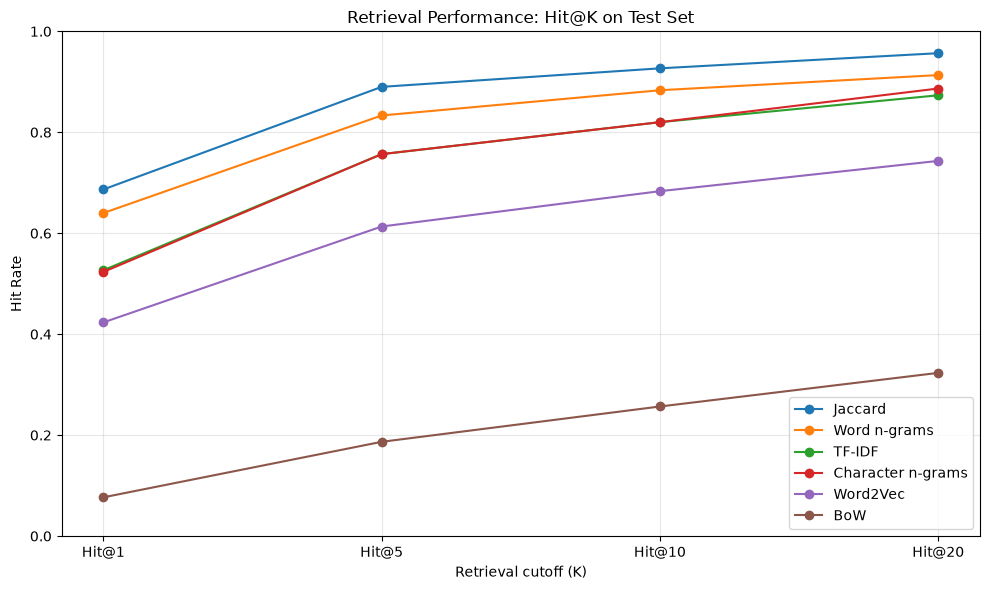

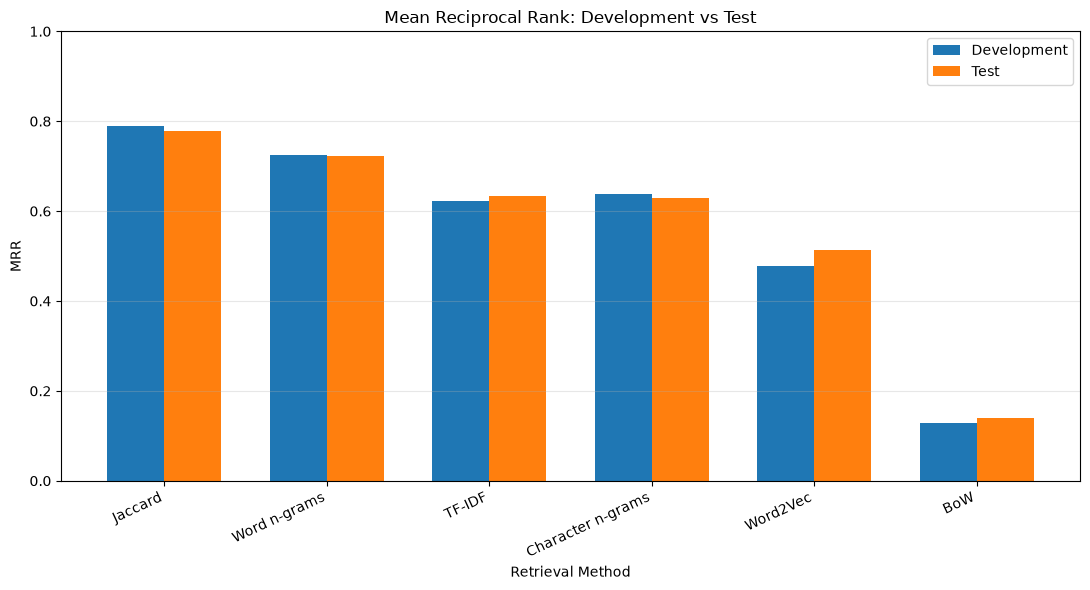

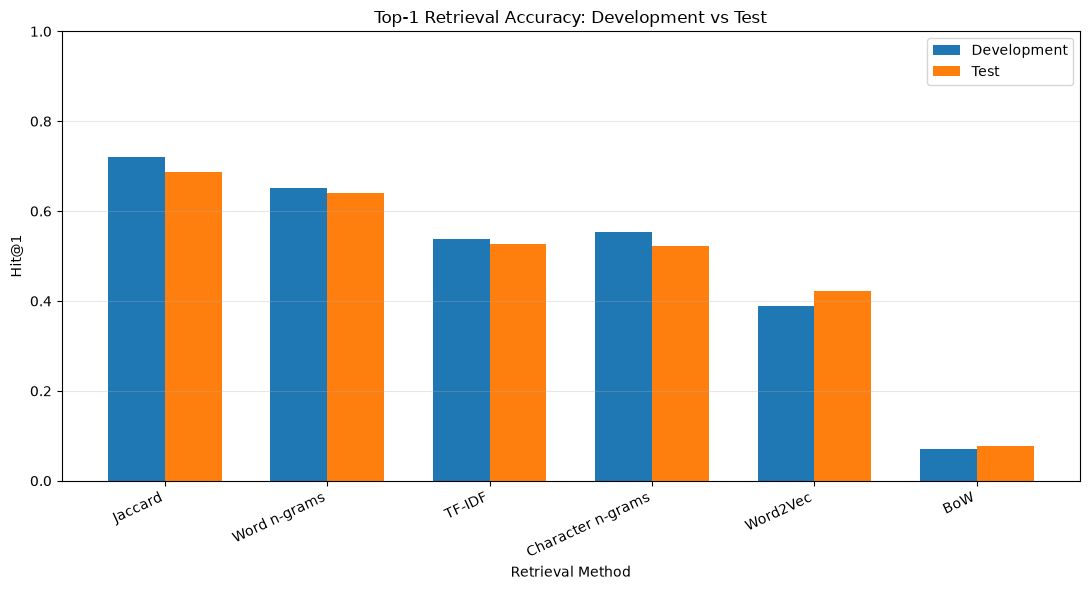


Figures saved successfully:
food11_class_distribution_final.png - 64.4 KB
food11_image_dimensions.png - 119.2 KB
food11_sample_grid.png - 2116.2 KB
hit_at_1_comparison.png - 113.2 KB
hit_at_k_comparison.png - 209.4 KB
mrr_comparison.png - 113.3 KB


In [62]:
import matplotlib.pyplot as plt
import numpy as np

FIGURES_DIR = REPORT_DIR / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

method_order = [
    "Jaccard",
    "Word n-grams",
    "TF-IDF",
    "Character n-grams",
    "Word2Vec",
    "BoW"
]

# Prepare data
test_df = (
    final_results_df[final_results_df["Split"] == "Test"]
    .set_index("Method")
    .loc[method_order]
)

development_df = (
    final_results_df[final_results_df["Split"] == "Development"]
    .set_index("Method")
    .loc[method_order]
)

# --------------------------------------------------
# Figure 1: Hit@K comparison on the test set
# --------------------------------------------------

hit_columns = ["Hit@1", "Hit@5", "Hit@10", "Hit@20"]

plt.figure(figsize=(10, 6))

for method in method_order:
    values = test_df.loc[method, hit_columns].values
    plt.plot(hit_columns, values, marker="o", label=method)

plt.title("Retrieval Performance: Hit@K on Test Set")
plt.xlabel("Retrieval cutoff (K)")
plt.ylabel("Hit Rate")
plt.ylim(0, 1)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "hit_at_k_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


# --------------------------------------------------
# Figure 2: MRR comparison
# --------------------------------------------------

x = np.arange(len(method_order))
width = 0.35

plt.figure(figsize=(11, 6))

plt.bar(
    x - width / 2,
    development_df["MRR"],
    width,
    label="Development"
)

plt.bar(
    x + width / 2,
    test_df["MRR"],
    width,
    label="Test"
)

plt.title("Mean Reciprocal Rank: Development vs Test")
plt.xlabel("Retrieval Method")
plt.ylabel("MRR")
plt.xticks(x, method_order, rotation=25, ha="right")
plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "mrr_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


# --------------------------------------------------
# Figure 3: Hit@1 comparison
# --------------------------------------------------

plt.figure(figsize=(11, 6))

plt.bar(
    x - width / 2,
    development_df["Hit@1"],
    width,
    label="Development"
)

plt.bar(
    x + width / 2,
    test_df["Hit@1"],
    width,
    label="Test"
)

plt.title("Top-1 Retrieval Accuracy: Development vs Test")
plt.xlabel("Retrieval Method")
plt.ylabel("Hit@1")
plt.xticks(x, method_order, rotation=25, ha="right")
plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "hit_at_1_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


print("\nFigures saved successfully:")
for path in sorted(FIGURES_DIR.glob("*.png")):
    print(path.name, "-", round(path.stat().st_size / 1024, 1), "KB")

In [63]:

report_content = r"""
# Step 2 — Classical NLP and Text Representations

## 1. Introduction

This stage implements and evaluates classical NLP techniques for ingredient-aware recipe retrieval using the Food.com recipe dataset.

The objective is to retrieve recipes from a collection of existing recipes based on a query containing a subset of ingredients. Each recipe is treated as a document, and the query is compared with the ingredient representation of every recipe to produce a ranked list.

The experiments cover text preprocessing, several text representation techniques, similarity-based document retrieval, and quantitative evaluation.

The main research question is:

**How effectively can different classical NLP representations retrieve the original recipe when given only a subset of its ingredients?**

## 2. Dataset and Benchmark Construction

### 2.1 Recipe corpus

The experiments use the Food.com RAW_recipes dataset.

- Total recipes: 231,637
- Primary retrieval corpus: 231,637 recipes
- Recipe information includes names, ingredients, descriptions, preparation steps, and nutrition information.
- Ingredient lists are used as the primary content for ingredient-aware retrieval.

The RAW_recipes dataset was selected as the primary corpus because it provides broader recipe coverage than the corresponding PP_recipes subset.

### 2.2 Query generation

A synthetic ingredient-based retrieval benchmark was constructed from the recipe corpus.

Recipes containing at least five ingredients were eligible for query generation.

- Eligible recipes: 210,035 (approximately 90.67%).
- Total queries: 1,000.
- Development queries: 700.
- Final test queries: 300.

For each query, approximately half of the source recipe's ingredients were selected, while at least two ingredients were kept hidden. The recipe name was excluded from the query.

The source recipe ID was retained as the known relevant document for evaluation.

The development and test query source IDs were separated using a reproducible random split. The full recipe corpus, including source recipes, remained searchable in both evaluations.

This design evaluates whether a recipe can be retrieved from an incomplete ingredient list. It is a query-held-out evaluation, not a corpus-held-out evaluation.

## 3. Text Preprocessing

The same general preprocessing approach was applied to recipe text and ingredient-based queries.

### 3.1 Normalization

Text normalization includes:

- Conversion to lowercase.
- Replacement of hyphens with spaces.
- Removal of punctuation and non-alphanumeric special characters.
- Removal of repeated whitespace.

### 3.2 Tokenization

Text is tokenized by splitting normalized text into individual words.

### 3.3 Stopword removal

English stopwords were removed using the NLTK English stopword list.

Additional structural terms were removed:

- recipe
- ingredients
- preparation

Negation and other potentially meaningful terms were protected from removal, including words such as `not`, `no`, `without`, and `never`.

### 3.4 Lemmatization

POS-aware lemmatization was performed using NLTK.

Verbs were lemmatized as verbs, while other tokens were treated as nouns.

For example:

- `breasts` becomes `breast`.
- `tomatoes` becomes `tomato`.
- `chopped` can be reduced to its base verb form.

### 3.5 Spelling normalization

A small mapping was applied to selected spelling variants:

| Original | Normalized |
|---|---|
| chilli | chili |
| yoghurt | yogurt |
| sautee | saute |
| barbeque | barbecue |
| catsup | ketchup |
| aubergine | eggplant |
| courgette | zucchini |

Potentially distinct regional ingredient names, such as cilantro and coriander, were kept separate.

### 3.6 Preprocessing example

Input:

`Chicken breasts, chopped onions, and fresh tomatoes`

Normalized and processed output:

`chicken breast chop onion fresh tomato`

### 3.7 Preprocessing considerations

The preprocessing pipeline aims to reduce superficial text variation while preserving ingredient meaning.

Stopword removal and lemmatization reduce unnecessary vocabulary variation. Spelling normalization addresses selected regional or spelling differences.

However, preprocessing can also remove useful information if applied too aggressively. Negation-related terms were therefore protected.

## 4. Text Representation Techniques

Several classical representations were implemented to compare lexical and semantic approaches.

### 4.1 Bag of Words (BoW)

Bag of Words represents each recipe as a vector of term frequencies.

Each dimension corresponds to a vocabulary term, and its value represents the term's occurrence in the recipe.

Configuration:

- `CountVectorizer`
- `min_df = 2`

Advantages:
- Simple and interpretable.
- Captures the presence and frequency of ingredient terms.

Limitations:
- Does not understand semantic similarity.
- Does not preserve word order.
- Common terms can produce many tied similarity scores.

### 4.2 TF-IDF

TF-IDF assigns greater importance to terms that are informative within the corpus and lower importance to terms appearing frequently across documents.

Configuration:

- `TfidfVectorizer`
- `min_df = 2`

TF-IDF helps distinguish recipes using less common ingredient terms. However, it still relies on lexical overlap and does not directly understand synonyms or semantic relationships.

### 4.3 Word n-grams

Word n-grams extend lexical representation by considering sequences of one or more consecutive words.

Configuration:

- TF-IDF representation.
- `ngram_range = (1, 2)`
- `min_df = 2`

This representation captures individual terms and adjacent two-word combinations. It can help preserve useful ingredient expressions and local word patterns.

### 4.4 Character n-grams

Character n-grams represent text using sequences of characters rather than complete words.

Configuration:

- `analyzer = "char_wb"`
- `ngram_range = (2, 5)`
- `min_df = 2`
- `max_features = 100000`

This approach can capture partial word similarities and spelling variations. However, character overlap does not necessarily indicate that two ingredients have equivalent culinary meanings.

### 4.5 Word2Vec

Word2Vec learns dense word embeddings from the recipe corpus using contextual word co-occurrence.

Configuration:

- Vector size: 100
- Window size: 5
- Minimum word frequency: 2
- Skip-gram architecture (`sg = 1`)
- Training epochs: 10
- Random seed: 42

A recipe representation is obtained by averaging the embeddings of its recognized tokens.

Two approaches were compared:

- Unweighted mean pooling.
- TF-IDF-weighted mean pooling.

Full-text and ingredient-only representations were also evaluated.

The best-performing Word2Vec configuration in development was the ingredient-only, unweighted representation.

Although Word2Vec captures semantic relationships between food-related words, mean pooling can lose information about ingredient combinations and their relative importance.

## 5. Classical Retrieval Method

### 5.1 Document retrieval formulation

The retrieval task is formulated as a similarity-based document retrieval problem.

- Each recipe is a document.
- The input ingredient list is a query.
- The recipe corpus is the searchable collection.
- A similarity score is calculated between the query and each recipe.
- Recipes are ranked from highest to lowest similarity.

The system returns the highest-ranked recipes as retrieval candidates.

This is an information retrieval task rather than a supervised classification task.

### 5.2 Jaccard similarity

Jaccard similarity was implemented as a phrase-level ingredient overlap method.

Each recipe is represented as a set of normalized ingredient phrases. Query ingredients are processed in the same way.

The similarity between query set Q and recipe set R is:

\[
J(Q,R)=\frac{|Q\cap R|}{|Q\cup R|}
\]

The score ranges from 0 to 1.

- 1 indicates identical ingredient sets.
- 0 indicates no shared ingredient phrases.
- Intermediate values indicate partial overlap.

The use of ingredient phrases preserves expressions such as `black pepper`, `olive oil`, and `green onion` rather than treating every word independently.

### 5.3 Cosine similarity

Cosine similarity was used for vector-based retrieval methods, including BoW, TF-IDF, word n-grams, character n-grams, and Word2Vec.

It compares the direction of the query and recipe vectors rather than their absolute magnitudes.

The recipes with the highest cosine similarity scores are ranked first.

## 6. Evaluation Protocol

### 6.1 Development and test separation

The benchmark contains two disjoint query sets:

| Split | Number of queries |
|---|---:|
| Development | 700 |
| Final test | 300 |
| Total | 1,000 |

Development results were used to compare methods and select the preferred approach.

The final test set was evaluated after method selection and was not used for tuning.

The searchable recipe corpus remained the same for both splits.

### 6.2 Ranking and tie handling

Equal similarity scores can occur, particularly with set-based and term-frequency representations.

A stable tie-breaking rule was used for the final test evaluation. Recipes with equal scores are ordered according to their original corpus order.

The development Jaccard and BoW results were also recalculated using this rule because their initial evaluations showed substantial tie effects.

The other development methods had negligible tie rates, so their original development metrics were retained.

### 6.3 Evaluation metrics

The following ranking metrics were used:

**Hit Rate at K (Hit@K)**

Measures the proportion of queries for which the known source recipe appears within the first K retrieved results.

\[
Hit@K=\frac{\text{Queries with source recipe in top K}}{\text{Total queries}}
\]

Higher values are better.

**Mean Reciprocal Rank (MRR)**

Measures the average reciprocal rank of the known source recipe.

\[
MRR=\frac{1}{N}\sum_{i=1}^{N}\frac{1}{rank_i}
\]

Higher values indicate that the source recipe tends to appear closer to the top of the ranking.

**Mean Rank and Median Rank**

Measure the average and median position of the source recipe. Lower values are better.

### 6.4 Evaluation limitations

Each query has one known relevant document: its original source recipe.

However, other recipes in the corpus may also be relevant to the same ingredient query. These additional relevant recipes are not fully annotated.

Therefore, the reported metrics measure retrieval of the known source recipe rather than complete semantic relevance.

Precision, recall, and F1-score were not used as primary metrics because the benchmark does not contain complete relevance labels for all retrieved recipes.

## 7. Experimental Results

### 7.1 Development results

The following results were obtained on the 700 development queries.

| Method | Hit@1 | Hit@5 | Hit@10 | Hit@20 | MRR |
|---|---:|---:|---:|---:|---:|
| Jaccard | 0.7214 | 0.8671 | 0.9200 | 0.9471 | 0.7892 |
| Word n-grams | 0.6514 | 0.8100 | 0.8586 | 0.8929 | 0.7254 |
| TF-IDF | 0.5371 | 0.7200 | 0.7986 | 0.8371 | 0.6226 |
| Character n-grams | 0.5529 | 0.7329 | 0.8029 | 0.8514 | 0.6376 |
| Word2Vec | 0.3886 | 0.5757 | 0.6600 | 0.7100 | 0.4775 |
| BoW | 0.0700 | 0.1700 | 0.2514 | 0.3229 | 0.1285 |

### 7.2 Final test results

The final evaluation was performed on the 300 untouched test queries.

| Method | Hit@1 | Hit@5 | Hit@10 | Hit@20 | MRR |
|---|---:|---:|---:|---:|---:|
| Jaccard | 0.6867 | 0.8900 | 0.9267 | 0.9567 | 0.7787 |
| Word n-grams | 0.6400 | 0.8333 | 0.8833 | 0.9133 | 0.7236 |
| TF-IDF | 0.5267 | 0.7567 | 0.8200 | 0.8733 | 0.6339 |
| Character n-grams | 0.5233 | 0.7567 | 0.8200 | 0.8867 | 0.6301 |
| Word2Vec | 0.4233 | 0.6133 | 0.6833 | 0.7433 | 0.5127 |
| BoW | 0.0767 | 0.1867 | 0.2567 | 0.3233 | 0.1393 |

### 7.3 Visual comparison

#### Hit Rate at K

![Hit at K comparison](figures/hit_at_k_comparison.png)

This figure compares the proportion of source recipes retrieved within different ranking cutoffs on the test set.

#### Mean Reciprocal Rank

![MRR comparison](figures/mrr_comparison.png)

This figure compares the ranking quality of each method across development and test queries.

#### Hit@1

![Hit at 1 comparison](figures/hit_at_1_comparison.png)

This figure compares the proportion of queries for which the source recipe was ranked first.

## 8. Discussion

### 8.1 Jaccard similarity

Jaccard achieved the strongest overall performance.

On the test set, it achieved:

- Hit@1: 68.67%.
- Hit@5: 89.00%.
- Hit@10: 92.67%.
- Hit@20: 95.67%.
- MRR: 0.7787.

This result is consistent with the benchmark design. Queries are constructed from subsets of the source recipes' ingredients, so ingredient overlap is a highly relevant signal.

### 8.2 Word n-grams

Word n-grams were the strongest lexical alternative.

They achieved a test Hit@1 of 64.00% and an MRR of 0.7236.

Considering both individual terms and adjacent word combinations provides a useful representation for ingredient-based retrieval.

### 8.3 TF-IDF and character n-grams

TF-IDF and character n-grams achieved intermediate performance.

TF-IDF gives more importance to informative terms, while character n-grams capture partial spelling similarities. Neither method outperformed Jaccard or word n-grams in this benchmark.

### 8.4 Word2Vec

Word2Vec achieved a test Hit@1 of 42.33% and an MRR of 0.5127.

Its semantic representations are useful for capturing relationships between food-related words. However, averaging embeddings into one recipe vector can blur the distinctions between ingredient combinations.

In this experiment, exact ingredient overlap and lexical patterns were more effective than the tested mean-pooled embeddings.

### 8.5 Bag of Words

BoW achieved substantially weaker performance after correcting its ranking ties.

Its original term-frequency representation produced many recipes with identical scores. This demonstrated the importance of handling ties consistently when evaluating retrieval systems.

## 9. Selected Baseline

Jaccard similarity was selected as the preferred classical NLP retrieval baseline.

The reasons are:

1. It achieved the highest Hit@1 and MRR on both development and test queries.
2. It achieved a test Hit@10 of 92.67%.
3. It directly models ingredient overlap.
4. It is computationally and conceptually straightforward.
5. Its behavior is interpretable, since the similarity score is based on shared ingredient phrases.

Word n-grams remain a useful secondary baseline because they achieved competitive results.

The selected method is appropriate for the current ingredient-subset retrieval benchmark. Its performance should not be interpreted as proof that it is universally superior for all recipe search tasks.

## 10. Limitations and Future Improvements

Several limitations should be considered:

- **Synthetic queries:** Queries were generated from existing recipes rather than collected from real users.
- **Incomplete relevance labels:** Only the original source recipe is guaranteed to be relevant.
- **Corpus overlap:** Source recipes remain in the searchable corpus by design. This evaluates query-held-out retrieval, not generalization to unseen recipes.
- **Exact ingredient matching:** Jaccard does not inherently recognize synonyms or semantically equivalent ingredients.
- **Ingredient quantities:** The retrieval benchmark does not model ingredient quantities or proportions.
- **Word2Vec pooling:** Mean pooling can lose ingredient-level distinctions and combinations.
- **Language coverage:** The preprocessing pipeline was designed primarily for English text.
- **Tie-breaking:** Stable corpus-order tie-breaking provides deterministic ranks but can influence the order of recipes with identical scores.

Potential future improvements include synonym-aware ingredient normalization, ingredient ontology integration, improved semantic retrieval, and evaluation using manually annotated relevance judgments.

## 11. Conclusion

This stage implemented a complete classical NLP retrieval pipeline using the Food.com recipe corpus.

Text preprocessing, multiple text representations, similarity-based document retrieval, and ranking evaluation were implemented and compared.

Across 700 development queries and 300 final test queries, Jaccard similarity achieved the strongest performance, followed by word n-gram TF-IDF retrieval.

The experiments demonstrate that simple ingredient-overlap methods can be highly effective when queries consist of incomplete ingredient lists from existing recipes.

Jaccard is therefore selected as the classical retrieval baseline for the next stages of the NutriVision project.
"""

report_path = REPORT_DIR / "Classical_NLP_Retrieval.md"
report_path.write_text(report_content.strip() + "\n", encoding="utf-8")

print("Report saved successfully:")
print(report_path)
print("\nFile size:", round(report_path.stat().st_size / 1024, 2), "KB")
print("Figures referenced:", len(list(FIGURES_DIR.glob("*.png"))))


Report saved successfully:
C:\Users\dell\NutriVision\reports\Classical_NLP_Retrieval.md

File size: 16.69 KB
Figures referenced: 6
